# Unifikacja AOD-4 i ds_drone_hel_plane dla YOLO26 (detekcja HBB)

Reprodukowalny potok do rozdziału 3/4 pracy inżynierskiej: inspekcja → walidacja
→ kontrola geometrii → deduplikacja i ochrona benchmarku → opcjonalne ptaki
→ kopiowanie transakcyjne → audyt końcowy. YOLO26 używa w detekcji tych samych
etykiet HBB `class_id x_center y_center width height` co YOLOv8.

**Wynik inspekcji lokalnej:** AOD-4 ma obrazy i etykiety w `{split}/{images,labels}`
(obsługiwany jest również wcześniejszy układ `Images/{split}/{images,labels}` oraz
oddzielny eksport `Annotations/YOLOv8 format`). `YOLOv8 OBB format` nie jest źródłem.
`ds_drone_hel_plane/data.yaml` deklaruje `AirPlane, Drone, Helicopter`, czyli
mapowanie **`{0: 0, 1: 2, 2: 3}`**. Kod ponownie sprawdza metadane przy uruchomieniu.
Źródła zawierają odpowiednio 22 516 i 10 756 obrazów, co nie oznacza liczby próbek po filtracji.

`/ISA/INŻ` nie istnieje na tej maszynie: rzeczywisty katalog to `/home/hubert/ISA/INŻ`.
Ścieżki są wykrywane względem projektu; YAML zawiera rzeczywistą ścieżkę bezwzględną.

Uruchamiaj komórki kolejno. Siatki przed kopiowaniem służą do oceny przez autora;
można zatrzymać wykonywanie po kroku 3 i przejrzeć PNG. Kod nie ocenia automatycznie
ciasności ramek. Źródła są tylko odczytywane, a istniejący wynik nigdy nie jest nadpisywany.
Ponowne wykonanie identycznego planu tylko weryfikuje istniejący wynik.

## 0. Środowisko i parametry

Python 3.11+. W razie brakujących zależności uruchom poniższą komórkę instalacji
po odkomentowaniu, następnie zrestartuj kernel. Dla samej weryfikacji wystarcza PyTorch CPU.
Wersje użyte w konkretnym przebiegu są zapisywane w `environment.json`.

In [1]:
# %pip install pandas matplotlib seaborn Pillow opencv-python PyYAML tqdm ImageHash \
#     ultralytics nbformat nbclient ipykernel tabulate

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import hashlib
import io
import json
import logging
import math
import os
import re
import shutil
import sys
import tempfile
import uuid

import cv2
import imagehash
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
import seaborn as sns
from tqdm.auto import tqdm
import yaml
from IPython.display import display, Markdown

def project_root():
    for candidate in (Path.cwd(), *Path.cwd().parents, Path('/ISA/INŻ')):
        if (candidate / 'datasets/AOD_4').is_dir() and (candidate / 'datasets/ds_drone_hel_plane').is_dir():
            return candidate.resolve()
    raise FileNotFoundError('Uruchom kernel w projekcie ISA/INŻ lub ustaw ROOT jawnie.')

ROOT = project_root()
AOD_ROOT = ROOT / 'datasets/AOD_4'
DS_ROOT = ROOT / 'datasets/ds_drone_hel_plane'
OUTPUT = ROOT / 'datasets/AOD_4_merged'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid.uuid4().hex[:8]
REPORT = ROOT / 'research/reports/dataset_unificator' / RUN_ID
REPORT.mkdir(parents=True, exist_ok=False)
TARGET = {0: 'airplane', 1: 'bird', 2: 'drone', 3: 'helicopter'}
SPLITS = ('train', 'valid', 'test')
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}
SEED = 20261026
HASH_WORKERS = min(8, os.cpu_count() or 1)
PHASH_RADIUS = 4                 # 64 bity, odległość Hamminga
DHASH_RADIUS = 6                 # dodatkowe potwierdzenie podobieństwa
PROTECT_KNOWN_VIDEO_GROUPS = True # całe rozpoznane sekwencje poza train, jeśli są w benchmarku
BIRD_MODE = 'off'                # off | filter | append
BIRD_WEIGHTS = None              # lokalny checkpoint AOD-4 lub COCO; brak pobierania modelu
BIRD_CONF = 0.45
BIRD_DEVICE = 'cpu'
COMMIT_DATASET = True            # False = pełna analiza i plan bez kopiowania

ImageFile.LOAD_TRUNCATED_IMAGES = False
cv2.setNumThreads(1)
sns.set_theme(style='whitegrid', context='paper', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'font.family': 'DejaVu Sans'})
logger = logging.getLogger('dataset_unificator')
logger.setLevel(logging.INFO)
for handler in logger.handlers[:]:
    handler.close()
    logger.removeHandler(handler)
for handler in (logging.StreamHandler(), logging.FileHandler(REPORT / 'pipeline.log', encoding='utf-8')):
    handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
    logger.addHandler(handler)
logger.propagate = False

def write_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

def save_table(frame, name, latex=False):
    frame.to_csv(REPORT / f'{name}.csv', index=False)
    frame.to_html(REPORT / f'{name}.html', index=False)
    if latex:
        frame.to_latex(REPORT / f'{name}.tex', index=False, escape=True)
    display(frame)

def save_figure(fig, name):
    fig.savefig(REPORT / f'{name}.png', bbox_inches='tight')
    fig.savefig(REPORT / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)

packages = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'Pillow', 'opencv-python',
            'PyYAML', 'tqdm', 'ImageHash', 'ultralytics', 'torch', 'torchvision']
environment = {'python': sys.version, 'executable': sys.executable}
for package in packages:
    try:
        environment[package] = version(package)
    except PackageNotFoundError:
        environment[package] = 'not installed'
write_json(REPORT / 'environment.json', environment)
logger.info('ROOT=%s | OUTPUT=%s | REPORT=%s', ROOT, OUTPUT, REPORT)

/home/hubert/ISA/INŻ/.venv/lib64/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-26 21:15:31,853 INFO ROOT=/home/hubert/ISA/INŻ | OUTPUT=/home/hubert/ISA/INŻ/datasets/AOD_4_merged | REPORT=/home/hubert/ISA/INŻ/research/reports/dataset_unificator/20261026T201531_60a225c2


## 1. EDA: struktura, dowód mapowania i parowanie

Metadane klas są obowiązkowe. Sprzeczne deklaracje przerywają pracę; brak metadanych
nie prowadzi do zgadywania po nazwach plików. Historyczne ścieżki absolutne w YAML
drugiego zbioru nie są używane do odczytu obrazów. Skan obejmuje całe drzewa katalogów,
ale zliczenia próbek i instancji dotyczą wyłącznie wybranego eksportu HBB.
Liczba wszystkich `.txt` w drzewie jest raportowana osobno od liczby etykiet.
Brak etykiety, błędna wielkość liter i etykieta osierocona są odróżnione od jawnego tła 0 B.

In [3]:
ALIASES = {'airplane': 'airplane', 'plane': 'airplane', 'drone': 'drone',
           'helicopter': 'helicopter', 'bird': 'bird'}

def canonical(name):
    key = str(name).strip().casefold()
    if key not in ALIASES:
        raise ValueError(f'Nieznana klasa: {name!r}')
    return ALIASES[key]

def normalize_names(value):
    if isinstance(value, list):
        result = dict(enumerate(value))
    elif isinstance(value, dict):
        result = {int(key): val for key, val in value.items()}
    else:
        raise ValueError('names musi być listą lub słownikiem.')
    if sorted(result) != list(range(len(result))):
        raise ValueError('ID klas muszą być ciągłe od 0.')
    result = {key: canonical(val) for key, val in result.items()}
    if len(set(result.values())) != len(result):
        raise ValueError('Zduplikowane nazwy klas po normalizacji.')
    return result

def scan_tree(root):
    rows, metadata = [], []
    for directory, dirs, files in os.walk(root, followlinks=False):
        folder = Path(directory)
        rows.append({'directory': str(folder.relative_to(root)), 'files': len(files),
                     'images': sum(Path(f).suffix.lower() in IMAGE_EXTS for f in files),
                     'txt': sum(Path(f).suffix.lower() == '.txt' for f in files),
                     'cache': sum(f.endswith('.cache') for f in files)})
        for name in sorted(files):
            if name.lower() in {'data.yaml', 'dataset.yaml', 'data.yml', 'dataset.yml', 'classes.txt'}:
                path = folder / name
                metadata.append(path)
                logger.info('METADATA %s\n%s', path, path.read_text(encoding='utf-8-sig'))
    return pd.DataFrame(rows), sorted(metadata)

trees, metadata_paths = {}, {}
for source, root in {'aod4': AOD_ROOT, 'ds3c': DS_ROOT}.items():
    trees[source], metadata_paths[source] = scan_tree(root)
    save_table(trees[source], f'tree_{source}')

def confirmed_names(paths):
    declarations, evidence = [], []
    for path in paths:
        if path.name.lower() == 'classes.txt':
            names = normalize_names([s.strip() for s in path.read_text(encoding='utf-8-sig').splitlines() if s.strip()])
        else:
            doc = yaml.safe_load(path.read_text(encoding='utf-8-sig'))
            if not isinstance(doc, dict) or 'names' not in doc:
                continue
            names = normalize_names(doc['names'])
            if 'nc' in doc and int(doc['nc']) != len(names):
                raise ValueError(f'Błędne nc: {path}')
        declarations.append(names)
        evidence.append({'path': str(path), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
                         'names': names, 'content': path.read_text(encoding='utf-8-sig')})
    if not declarations or any(d != declarations[0] for d in declarations):
        raise ValueError('Brak jednoznacznego potwierdzenia mapowania w metadanych.')
    return declarations[0], evidence

AOD_NAMES, aod_evidence = confirmed_names(metadata_paths['aod4'])
DS_NAMES, ds_evidence = confirmed_names(metadata_paths['ds3c'])
if AOD_NAMES != TARGET or set(DS_NAMES.values()) != {'airplane', 'drone', 'helicopter'}:
    raise ValueError(f'Nieoczekiwane klasy: AOD={AOD_NAMES}, DS={DS_NAMES}')
target_ids = {name: class_id for class_id, name in TARGET.items()}
MAPPINGS = {'aod4': {i: i for i in TARGET},
            'ds3c': {old: target_ids[name] for old, name in DS_NAMES.items()}}
write_json(REPORT / 'class_mapping_evidence.json', {'aod4': aod_evidence, 'ds3c': ds_evidence, 'mappings': MAPPINGS})
save_table(pd.DataFrame([{'source': s, 'source_id': old, 'target_id': new, 'class': TARGET[new]}
                        for s, mapping in MAPPINGS.items() for old, new in mapping.items()]), 'class_mapping')

def detect_aod_layout(root):
    candidates = [(root, root), (root / 'Images', root / 'Images'),
                  (root / 'Images', root / 'Annotations/YOLOv8 format')]
    matches = []
    for image_base, label_base in candidates:
        layouts = {}
        for split in SPLITS:
            image_dir = image_base / split / 'images'
            if not image_dir.is_dir():
                image_dir = image_base / split
            label_options = [label_base / split / 'labels']
            if label_base != image_base:
                label_options.append(label_base / split)
            label_dir = next((d for d in label_options if d.is_dir() and any(d.glob('*.txt'))), None)
            if label_dir is not None and image_dir.is_dir():
                layouts[split] = (image_dir, label_dir)
        if len(layouts) == 3:
            matches.append(layouts)
    if len(matches) != 1:
        raise ValueError(f'Niejednoznaczny lub niekompletny eksport HBB AOD-4: {len(matches)}')
    return matches[0]

LAYOUTS = {'aod4': detect_aod_layout(AOD_ROOT),
           'ds3c': {s: (DS_ROOT / s / 'images', DS_ROOT / s / 'labels') for s in SPLITS}}

2026-10-26 21:15:31,900 INFO METADATA /home/hubert/ISA/INŻ/datasets/AOD_4/dataset.yaml
path: .

train: train/images
val: valid/images
test: test/images

names:
  0: airplane
  1: bird
  2: drone
  3: helicopter


,directory,files,images,txt,cache
0,.,1,0,0,0
1,test,0,0,0,0
2,test/images,2241,2241,0,0
3,test/labels,2241,0,2241,0
4,train,0,0,0,0
5,train/images,15761,15761,0,0
6,train/labels,15761,0,15761,0
7,valid,0,0,0,0
8,valid/images,4514,4514,0,0
9,valid/labels,4514,0,4514,0


2026-10-26 21:15:32,429 INFO METADATA /home/hubert/ISA/INŻ/datasets/ds_drone_hel_plane/data.yaml
train: "/home/hubert/ISA/sem 5/Sieci Neuronowe/Project 2/dataset/train/images"
val: "/home/hubert/ISA/sem 5/Sieci Neuronowe/Project 2/dataset/valid/images"
test: "/home/hubert/ISA/sem 5/Sieci Neuronowe/Project 2/dataset/test/images"

nc: 3
names: ["AirPlane", "Drone", "Helicopter"]



,directory,files,images,txt,cache
0,.,1,0,0,0
1,test,0,0,0,0
2,test/images,617,617,0,0
3,test/labels,617,0,617,0
4,train,1,0,0,1
5,train/images,9498,9498,0,0
6,train/labels,9498,0,9498,0
7,valid,1,0,0,1
8,valid/images,641,641,0,0
9,valid/labels,641,0,641,0


,source,source_id,target_id,class
0,aod4,0,0,airplane
1,aod4,1,1,bird
2,aod4,2,2,drone
3,aod4,3,3,helicopter
4,ds3c,0,0,airplane
5,ds3c,1,2,drone
6,ds3c,2,3,helicopter


In [4]:
@dataclass
class Sample:
    uid: str
    source: str
    split: str
    image: Path
    label: Path | None
    boxes: list = field(default_factory=list)
    raw_counts: Counter = field(default_factory=Counter)
    label_sha: str = ''
    image_sha: str = ''
    pixel_sha: str = ''
    valid: bool = False
    zero_bytes: bool = False
    phash: int | None = None
    dhash: int | None = None
    image_size: tuple = ()
    group: str | None = None
    reason: str = ''
    pseudo: list = field(default_factory=list)

events = []
def event(kind, path, detail, line=None, source=None, split=None):
    events.append({'kind': kind, 'path': str(path), 'line': line,
                   'detail': str(detail), 'source': source, 'split': split})
    logger.warning('%s | %s | line=%s | %s', kind, path, line, detail)

records, inventories = [], []
for source, layout in LAYOUTS.items():
    for split, (image_dir, label_dir) in layout.items():
        if not image_dir.is_dir() or not label_dir.is_dir():
            raise FileNotFoundError((image_dir, label_dir))
        images = sorted(p for p in image_dir.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
        labels = sorted(p for p in label_dir.rglob('*') if p.is_file() and p.suffix.lower() == '.txt')
        image_keys, label_keys = defaultdict(list), defaultdict(list)
        for p in images:
            image_keys[p.relative_to(image_dir).with_suffix('').as_posix()].append(p)
        for p in labels:
            label_keys[p.relative_to(label_dir).with_suffix('').as_posix()].append(p)
        lower_keys = defaultdict(list)
        for key in label_keys:
            lower_keys[key.casefold()].append(key)
        missing = sum(key not in label_keys for key in image_keys)
        orphan = sum(key not in image_keys for key in label_keys)
        inventories.append({'source': source, 'split': split, 'images': len(images),
                            'label_txt': len(labels), 'zero_byte_backgrounds': sum(p.stat().st_size == 0 for p in labels),
                            'missing_labels': missing, 'orphan_labels': orphan,
                            'all_tree_txt': int(trees[source]['txt'].sum())})
        for key, paths in label_keys.items():
            if key not in image_keys:
                event('orphan_label', paths[0], 'Etykieta bez obrazu; nie jest kopiowana.', source=source, split=split)
        for key, paths in image_keys.items():
            label_paths = label_keys.get(key, [])
            for image in paths:
                uid = f'{source}:{split}:{image.relative_to(image_dir).as_posix()}'
                sample = Sample(uid, source, split, image, label_paths[0] if len(label_paths) == 1 else None)
                if len(paths) != 1 or len(label_paths) > 1:
                    sample.reason = 'ambiguous_pair'
                    event('ambiguous_pair', image, key, source=source, split=split)
                elif not label_paths:
                    sample.reason = 'missing_label'
                    event('missing_label', image, {'case_candidates': lower_keys.get(key.casefold(), [])}, source=source, split=split)
                elif label_paths[0].suffix != '.txt':
                    sample.reason = 'case_mismatch'
                    event('case_mismatch', label_paths[0], 'Wymagane dokładne rozszerzenie .txt.', source=source, split=split)
                records.append(sample)
inventory = pd.DataFrame(inventories)
save_table(inventory, 'input_inventory', latex=True)
assert len({r.uid for r in records}) == len(records)

,source,split,images,label_txt,zero_byte_backgrounds,missing_labels,orphan_labels,all_tree_txt
0,aod4,train,15761,15761,415,0,0,22516
1,aod4,valid,4514,4514,125,0,0,22516
2,aod4,test,2241,2241,56,0,0,22516
3,ds3c,train,9498,9498,3,0,0,10756
4,ds3c,valid,641,641,1,0,0,10756
5,ds3c,test,617,617,0,0,0,10756


## 2. Walidacja HBB i remapowanie

Odrzucamy **całą próbkę treningową**, jeżeli choć jedna linia jest uszkodzona.
Usunięcie samej błędnej linii stworzyłoby nieoznaczony obiekt (fałszywe tło).
Nie konwertujemy automatycznie wielokątów ani nie przycinamy ramek: zmieniałoby to
geometrię używaną w estymacji odległości. Wymagamy liczb skończonych, całkowitego ID,
pięciu pól, normalizacji i dodatniego rozmiaru; kontrolujemy też narożniki ramki.
Tolerancja narożników 1e-6 obejmuje tylko zaokrąglenia zapisu.
Uszkodzona próbka w `valid/test` zatrzyma eksport, ponieważ benchmark musi pozostać cały.

In [5]:
def validate_hbb_line(line, mapping):
    tokens = line.split()
    if len(tokens) != 5:
        raise ValueError(f'expected_5_fields_got_{len(tokens)} (OBB/polygon nie jest HBB)')
    values = [float(token) for token in tokens]
    if not all(math.isfinite(v) for v in values):
        raise ValueError('non_finite')
    cls, x, y, w, h = values
    if not cls.is_integer() or int(cls) not in mapping:
        raise ValueError(f'invalid_class_{cls}')
    if not all(0 <= v <= 1 for v in (x, y, w, h)) or w <= 0 or h <= 0:
        raise ValueError('invalid_normalized_xywh')
    if min(x - w / 2, y - h / 2) < -1e-6 or max(x + w / 2, y + h / 2) > 1 + 1e-6:
        raise ValueError('box_outside_image')
    return (mapping[int(cls)], x, y, w, h)

def validate_sample(sample):
    if sample.label is None or sample.reason:
        return
    mapping = MAPPINGS[sample.source]
    try:
        raw = sample.label.read_bytes()
        sample.label_sha = hashlib.sha256(raw).hexdigest()
        sample.zero_bytes = len(raw) == 0
        lines = raw.decode('utf-8-sig').splitlines()
    except (OSError, UnicodeError) as exc:
        sample.reason = 'label_read_error'
        event(sample.reason, sample.label, repr(exc), source=sample.source, split=sample.split)
        return
    bad = False
    for line_number, line in enumerate(lines, 1):
        if not line.strip():
            continue
        # Rozkład źródłowy: ID odczytane z każdej linii, także o błędnej geometrii.
        try:
            raw_cls = float(line.split()[0])
            if math.isfinite(raw_cls) and raw_cls.is_integer() and int(raw_cls) in mapping:
                sample.raw_counts[mapping[int(raw_cls)]] += 1
        except (ValueError, IndexError):
            pass
        try:
            sample.boxes.append(validate_hbb_line(line, mapping))
        except ValueError as exc:
            bad = True
            event('invalid_annotation', sample.label, f'{exc}: {line}', line_number, sample.source, sample.split)
    sample.valid = not bad
    if bad:
        sample.reason = 'invalid_annotation'

for sample in tqdm(records, desc='Walidacja etykiet HBB'):
    validate_sample(sample)

source_counts = pd.DataFrame([
    {'source': source, 'split': split, 'class_id': cls, 'class': name,
     'raw_instances': sum(r.raw_counts[cls] for r in records if r.source == source and r.split == split),
     'validated_instances': sum(sum(b[0] == cls for b in r.boxes) for r in records if r.source == source and r.split == split and r.valid)}
    for source in LAYOUTS for split in SPLITS for cls, name in TARGET.items()
])
save_table(source_counts, 'input_class_instances', latex=True)
save_table(pd.DataFrame(events), 'validation_events')
logger.info('Poprawne etykiety: %d/%d; puste 0 B: %d', sum(r.valid for r in records), len(records), sum(r.zero_bytes for r in records))

Walidacja etykiet HBB:   0%|          | 0/33272 [00:00<?, ?it/s]

Walidacja etykiet HBB:   7%|▋         | 2297/33272 [00:00<00:01, 22650.81it/s]

Walidacja etykiet HBB:  14%|█▍        | 4582/33272 [00:00<00:01, 22760.87it/s]

Walidacja etykiet HBB:  21%|██        | 6859/33272 [00:00<00:01, 21854.65it/s]

Walidacja etykiet HBB:  27%|██▋       | 9049/33272 [00:00<00:01, 20026.85it/s]

Walidacja etykiet HBB:  33%|███▎      | 11072/33272 [00:00<00:01, 18993.51it/s]

... (13 outputs left out)

Walidacja etykiet HBB: 100%|██████████| 33272/33272 [00:01<00:00, 22574.18it/s]

,source,split,class_id,class,raw_instances,validated_instances
0,aod4,train,0,airplane,5508,5505
1,aod4,train,1,bird,5522,5522
2,aod4,train,2,drone,5500,5500
3,aod4,train,3,helicopter,5528,5528
4,aod4,valid,0,airplane,1625,1625
5,aod4,valid,1,bird,1557,1557
6,aod4,valid,2,drone,1602,1602
7,aod4,valid,3,helicopter,1585,1585
8,aod4,test,0,airplane,767,767
9,aod4,test,1,bird,821,821


,kind,path,line,detail,source,split
0,invalid_annotation,/home/hubert/ISA/INŻ/datasets/AOD_4/train/labe...,1,expected_5_fields_got_27 (OBB/polygon nie jest...,aod4,train
1,invalid_annotation,/home/hubert/ISA/INŻ/datasets/AOD_4/train/labe...,1,expected_5_fields_got_21 (OBB/polygon nie jest...,aod4,train
2,invalid_annotation,/home/hubert/ISA/INŻ/datasets/AOD_4/train/labe...,1,expected_5_fields_got_21 (OBB/polygon nie jest...,aod4,train
3,invalid_annotation,/home/hubert/ISA/INŻ/datasets/ds_drone_hel_pla...,1,box_outside_image: 1 0.514 0.33 0.973 0.549,ds3c,train
4,invalid_annotation,/home/hubert/ISA/INŻ/datasets/ds_drone_hel_pla...,1,box_outside_image: 1 0.515 0.294 0.971 0.48,ds3c,train


2026-10-26 21:15:37,979 INFO Poprawne etykiety: 33267/33272; puste 0 B: 600


## 3. Geometria i ręczna kontrola ciasności przed kopiowaniem

Losowanie 16 obrazów na źródło ma stały seed i obejmuje poprawne etykiety po remapowaniu.
Siatki nie są reprezentatywnym testem jakości wszystkich adnotacji. Rozkłady `w`, `h`,
pola i proporcji pokazują kandydatów do inspekcji, nie dowodzą marginesu tła.
Nie zmieniamy rozmiarów ramek na podstawie samych statystyk.

W modelu stadiometrycznym `Z ≈ f · D / d_px`, błąd pozornego rozmiaru ramki
przekłada się na błąd odległości. Same HBB, BoT-SORT i filtr Kalmana nie zapewniają
metrycznej rekonstrukcji 3D ani TTC: potrzebne są kalibracja, model rozmiaru obiektu
i estymacja ruchu. Ocena ramek jest jednym z elementów walidacji takiego systemu.

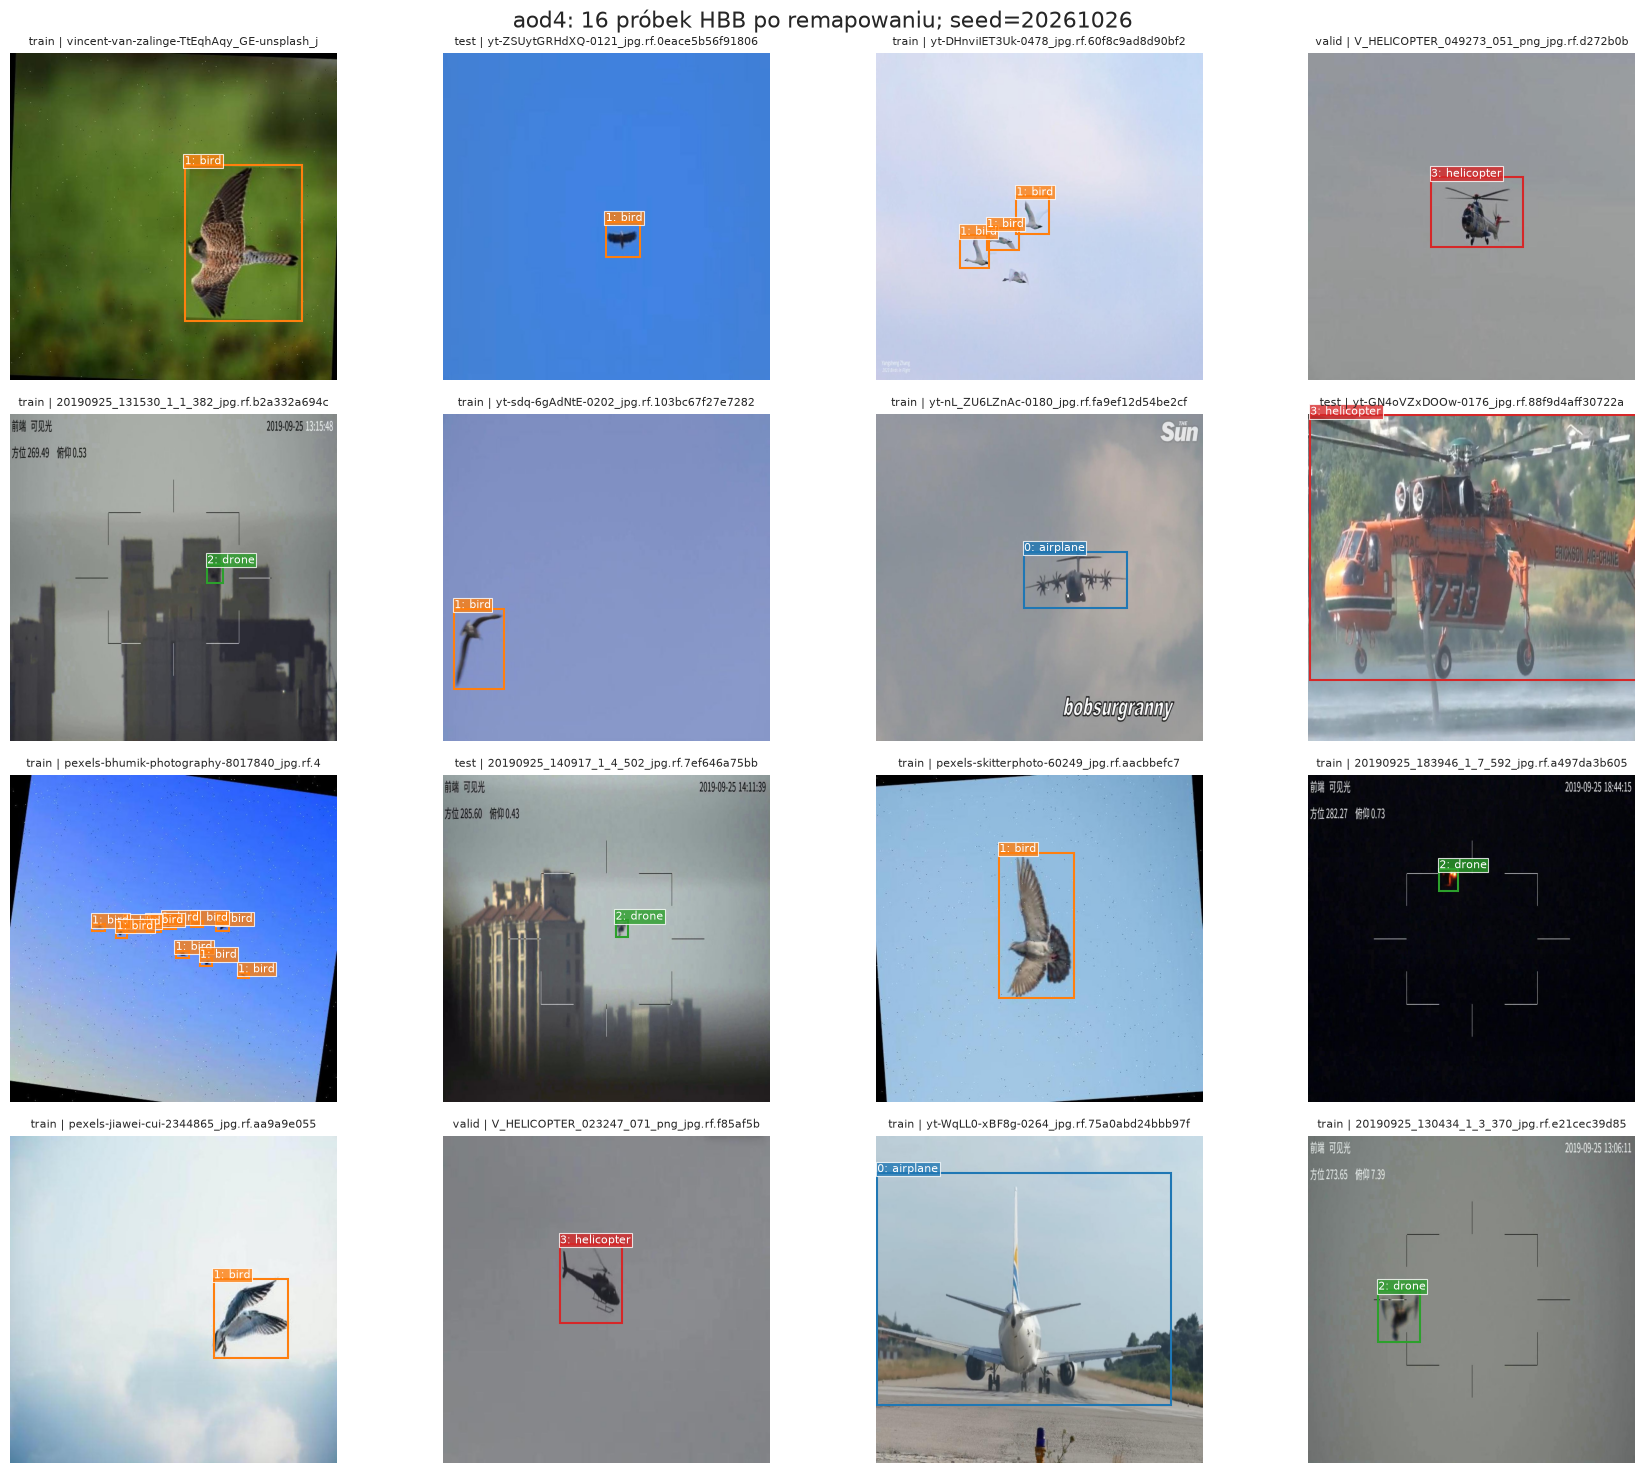

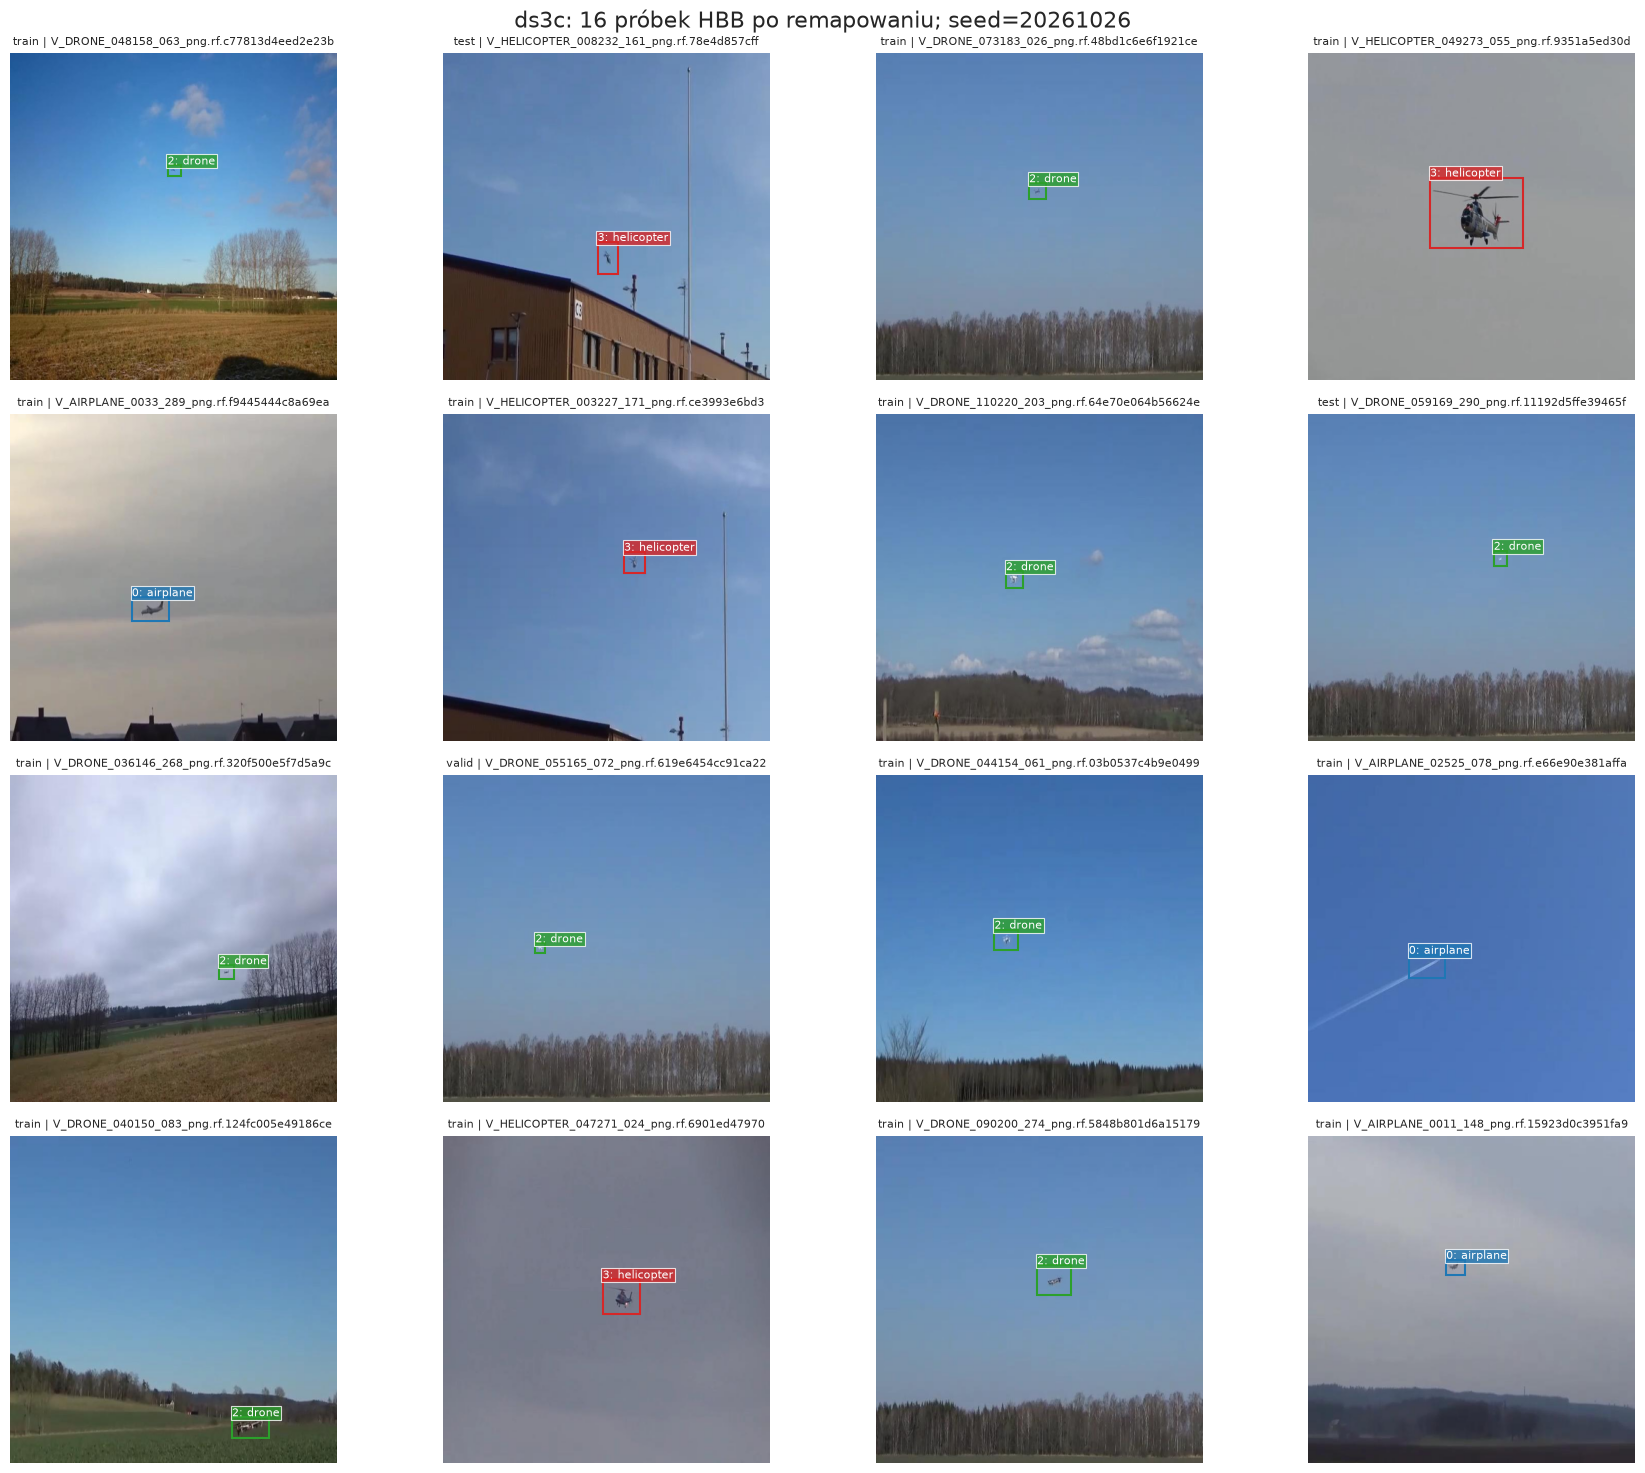

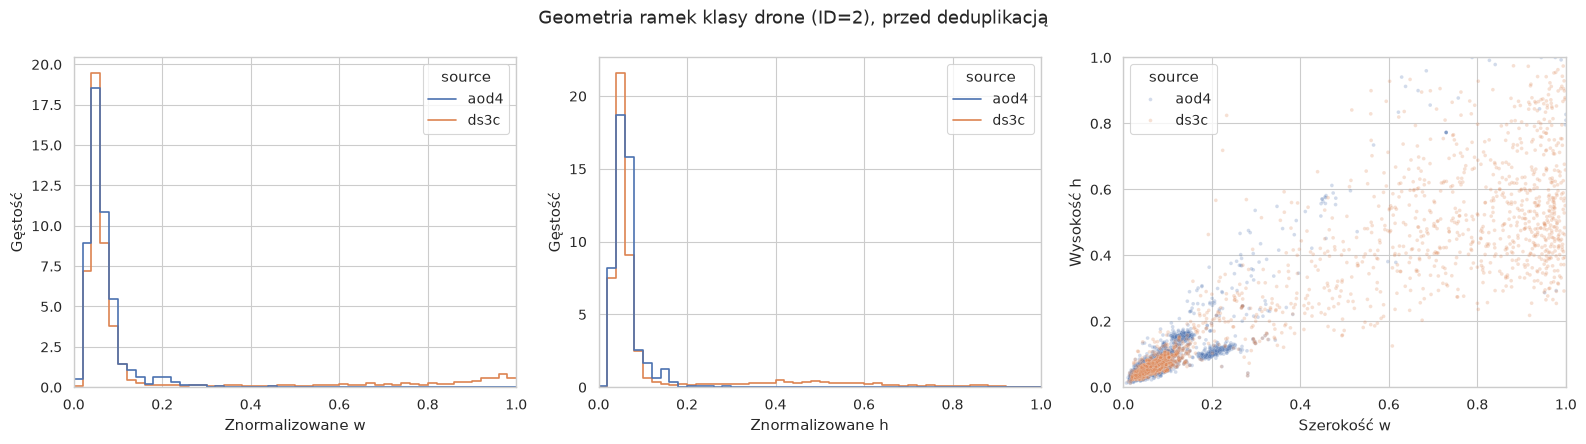

w                                                              \
         count      mean       std       min        1%       50%       95%   
source                                                                       
aod4    7898.0  0.070029  0.063279  0.006836  0.019531  0.056152  0.169922   
ds3c    5852.0  0.168882  0.267624  0.011000  0.025781  0.057813  0.919357   

                                 h  ...      area  aspect                      \
             99%       max   count  ...       max   count      mean       std   
source                              ...                                         
aod4    0.289077  1.000000  7898.0  ...  0.982012  7898.0  1.053730  0.375831   
ds3c    0.982528  0.999023  5852.0  ...  0.968156  5852.0  1.161832  0.404431   

                                                                    
             min        1%       50%       95%       99%       max  
source                                                              
aod4    0.325581  0.524088  0.954372  1.783585  2.072920  8.000000  
ds3c    0.283167  0.624806  1.075758  1.929244  2.736941  8.159091  

[2 rows x 36 columns]

In [6]:
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

def show_samples(samples, source, n=16, seed=SEED):
    candidates = [r for r in samples if r.source == source and r.valid]
    rng = np.random.default_rng(seed)
    chosen = [candidates[int(i)] for i in rng.choice(len(candidates), min(n, len(candidates)), replace=False)]
    fig, axes = plt.subplots(4, 4, figsize=(18, 15))
    for ax in axes.flat:
        ax.axis('off')
    for ax, sample in zip(axes.flat, chosen):
        try:
            with Image.open(sample.image) as image:
                image = image.convert('RGB')
                width, height = image.size
                ax.imshow(image)
            for cls, x, y, w, h in sample.boxes:
                x1, y1 = (x - w / 2) * width, (y - h / 2) * height
                ax.add_patch(Rectangle((x1, y1), w * width, h * height, fill=False, edgecolor=COLORS[cls], linewidth=1.5))
                ax.text(x1, max(0, y1 - 2), f'{cls}: {TARGET[cls]}', color='white', fontsize=8,
                        bbox={'facecolor': COLORS[cls], 'alpha': 0.8, 'pad': 1})
            ax.set_title(f'{sample.split} | {sample.image.name[:42]}' + (' | tło' if not sample.boxes else ''), fontsize=8)
        except (OSError, ValueError) as exc:
            ax.set_title(f'Błąd odczytu: {sample.image.name}', fontsize=8)
            event('preview_error', sample.image, repr(exc))
    fig.suptitle(f'{source}: 16 próbek HBB po remapowaniu; seed={seed}', fontsize=16)
    fig.tight_layout()
    save_figure(fig, f'tightness_{source}_16')
    return [r.uid for r in chosen]

preview_ids = {source: show_samples(records, source) for source in LAYOUTS}
write_json(REPORT / 'preview_samples.json', preview_ids)

box_frame = pd.DataFrame([
    {'uid': r.uid, 'source': r.source, 'class_id': b[0], 'w': b[3], 'h': b[4],
     'area': b[3] * b[4], 'aspect': b[3] / b[4]}
    for r in records if r.valid for b in r.boxes
])
drone_boxes = box_frame.loc[box_frame.class_id == 2].copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column in zip(axes[:2], ('w', 'h')):
    sns.histplot(data=drone_boxes, x=column, hue='source', bins=np.linspace(0, 1, 51),
                 stat='density', common_norm=False, element='step', fill=False, ax=ax)
    ax.set(xlabel=f'Znormalizowane {column}', ylabel='Gęstość', xlim=(0, 1))
sns.scatterplot(data=drone_boxes, x='w', y='h', hue='source', s=7, alpha=0.25, ax=axes[2])
axes[2].set(xlabel='Szerokość w', ylabel='Wysokość h', xlim=(0, 1), ylim=(0, 1))
fig.suptitle('Geometria ramek klasy drone (ID=2), przed deduplikacją')
fig.tight_layout()
save_figure(fig, 'drone_wh_distributions')
drone_stats = drone_boxes.groupby('source')[['w', 'h', 'area', 'aspect']].describe(percentiles=[0.01, 0.5, 0.95, 0.99])
drone_stats.to_csv(REPORT / 'drone_geometry_statistics.csv')
display(drone_stats)
drone_boxes.sort_values('area', ascending=False).head(50).to_csv(REPORT / 'drone_largest_boxes_review.csv', index=False)

## 4. Hashe, sekwencje źródłowe i ochrona benchmarku

Dla **wszystkich** obrazów obliczamy SHA-256 pliku, SHA-256 zdekodowanych pikseli,
64-bitowy pHash oraz dHash. BK-tree wyszukuje kandydatów bez tworzenia macierzy N×N.
Za podobne uznajemy obrazy z `pHash ≤ 4` **i** `dHash ≤ 6`; identyczne pliki lub piksele
są łączone niezależnie. Spójne składowe grafu uwzględniają łańcuchy A≈B≈C.
Jest to konserwatywny filtr: hashe mogą pomylić podobne tło nieba i nie gwarantują
wykrycia wszystkich transformacji. Progi są parametrami, a raport zawiera pary do inspekcji.

Drugi graf rozszerza połączenia o rozpoznane sekwencje: `V_CLASS_video_frame`,
`yt-YouTubeID-frame` oraz `YYYYMMDD_HHMMSS_segment_segment_frame`.
Usunięcie `.rf.<hash>` i końcówek eksportu pozwala łączyć nazwy między zbiorami.
Nazwy są wskazówką pochodzenia, nie pełną metryką podobieństwa: nierozpoznane sekwencje
pozostają jawnie raportowane. Domyślnie chronimy całe znane grupy benchmarku,
co może usunąć większość oryginalnego treningu AOD-4.

Priorytet: **każdy oryginalny AOD valid/test → AOD train → ds3c ze wszystkich splitów do train**.
Próbki treningowe ze składowej dotykającej benchmarku są odrzucane. Następnie usuwamy
duplikaty ds3c względem całego AOD oraz powtórzenia wewnątrz treningu. Samo pochodzenie
z jednego filmu nie powoduje redukcji treningu do jednej klatki.
Powiązania `valid ↔ test` są raportowane; ich usunięcie naruszałoby wymaganie
nienaruszonego benchmarku. Nie określamy go jako niezależnego, jeśli takie powiązania istnieją.

In [7]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def video_group(stem):
    name = stem.split('.rf.')[0]
    patterns = (
        r'^(V_(?:AIRPLANE|DRONE|HELICOPTER)_\d+)_\d+(?:_|$)',
        r'^(yt-.{11})-\d+(?:_|$)',
        r'^(\d{8}_\d{6}(?:_\d+){2})_\d+(?:_|$)',
    )
    for pattern in patterns:
        match = re.match(pattern, name, re.IGNORECASE)
        if match:
            return match.group(1).casefold()
    return None

def image_fingerprint(sample):
    try:
        with Image.open(sample.image) as image:
            image.verify()
        with Image.open(sample.image) as image:
            validation_issue = None
            if image.getexif().get(274, 1) != 1:
                validation_issue = 'EXIF orientation != 1: wymagana jawna kontrola zgodności z etykietą.'
            image = image.convert('RGB')
            image.load()
            if min(image.size) < 10:
                validation_issue = 'Image smaller than 10 px'
            pixels = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            return (sha256_file(sample.image), pixels, int(str(imagehash.phash(image)), 16),
                    int(str(imagehash.dhash(image)), 16), image.size, validation_issue)
    except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as exc:
        return ('', '', None, None, (), repr(exc))

with ThreadPoolExecutor(max_workers=HASH_WORKERS) as pool:
    for sample, result in zip(records, tqdm(pool.map(image_fingerprint, records), total=len(records), desc='Hashe i integralność obrazów')):
        sample.image_sha, sample.pixel_sha, sample.phash, sample.dhash, sample.image_size, error = result
        sample.group = video_group(sample.image.stem)
        if error:
            sample.valid = False
            sample.reason = 'image_validation_error' if sample.phash is not None else 'image_read_error'
            event(sample.reason, sample.image, error, source=sample.source, split=sample.split)

hash_table = pd.DataFrame([
    {'uid': r.uid, 'source': r.source, 'split': r.split, 'image': str(r.image),
     'sha256': r.image_sha, 'pixel_sha256': r.pixel_sha,
     'phash': f'{r.phash:016x}' if r.phash is not None else '',
     'dhash': f'{r.dhash:016x}' if r.dhash is not None else '',
     'width': r.image_size[0] if r.image_size else None,
     'height': r.image_size[1] if r.image_size else None,
     'video_group': r.group, 'valid_annotation_and_image': r.valid}
    for r in records
])
hash_table.to_csv(REPORT / 'all_image_hashes.csv', index=False)
write_json(REPORT / 'validation_events.json', events)

bad_benchmark = [r.uid for r in records if r.source == 'aod4' and r.split != 'train' and not r.valid]
if bad_benchmark:
    raise RuntimeError(f'Benchmark wymaga naprawy u źródła; eksport zablokowany: {bad_benchmark[:20]}')

Hashe i integralność obrazów:   0%|          | 0/33272 [00:00<?, ?it/s]

Hashe i integralność obrazów:   0%|          | 20/33272 [00:00<02:53, 192.03it/s]

Hashe i integralność obrazów:   0%|          | 45/33272 [00:00<02:35, 214.10it/s]

Hashe i integralność obrazów:   0%|          | 69/33272 [00:00<02:27, 224.46it/s]

Hashe i integralność obrazów:   0%|          | 92/33272 [00:00<02:30, 219.75it/s]

Hashe i integralność obrazów:   0%|          | 114/33272 [00:00<02:44, 200.98it/s]

... (1,230 outputs left out)

Hashe i integralność obrazów: 100%|█████████▉| 33183/33272 [02:17<00:00, 262.68it/s]

Hashe i integralność obrazów: 100%|█████████▉| 33220/33272 [02:17<00:00, 250.92it/s]

Hashe i integralność obrazów: 100%|█████████▉| 33252/33272 [02:17<00:00, 246.91it/s]

Hashe i integralność obrazów: 100%|█████████▉| 33271/33272 [02:17<00:00, 241.68it/s]

In [8]:
class UnionFind:
    def __init__(self, count):
        self.parent = list(range(count))
        self.rank = [0] * count

    def find(self, value):
        while self.parent[value] != value:
            self.parent[value] = self.parent[self.parent[value]]
            value = self.parent[value]
        return value

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a == b:
            return False
        if self.rank[a] < self.rank[b]:
            a, b = b, a
        self.parent[b] = a
        if self.rank[a] == self.rank[b]:
            self.rank[a] += 1
        return True

class BKTree:
    # Jeden węzeł na wartość pHash; bucket rozróżnia różne dHash.
    def __init__(self):
        self.root = None

    def add(self, value, payload):
        node = self.root
        if node is None:
            self.root = [value, [payload], {}]
            return
        while True:
            distance = (value ^ node[0]).bit_count()
            if distance == 0:
                node[1].append(payload)
                return
            if distance not in node[2]:
                node[2][distance] = [value, [payload], {}]
                return
            node = node[2][distance]

    def search(self, value, radius):
        stack = [self.root] if self.root else []
        while stack:
            node = stack.pop()
            distance = (value ^ node[0]).bit_count()
            if distance <= radius:
                for payload in node[1]:
                    yield distance, payload
            stack.extend(child for edge, child in node[2].items() if distance - radius <= edge <= distance + radius)

def build_duplicate_graph(samples, phash_radius=PHASH_RADIUS, dhash_radius=DHASH_RADIUS):
    uf, tree = UnionFind(len(samples)), BKTree()
    exact_file, exact_pixels, hash_pairs = {}, {}, {}
    edges = []
    def connect(i, j, kind, pdist=None, ddist=None):
        if uf.union(i, j):
            edges.append({'left': samples[i].uid, 'right': samples[j].uid, 'kind': kind,
                          'phash_distance': pdist, 'dhash_distance': ddist})
    for i, sample in enumerate(tqdm(samples, desc='Graf duplikatów')):
        if sample.phash is None:
            continue
        for lookup, key, kind in ((exact_file, sample.image_sha, 'sha256'), (exact_pixels, sample.pixel_sha, 'pixels')):
            if key in lookup:
                connect(i, lookup[key], kind, 0, 0)
            else:
                lookup[key] = i
        pair = (sample.phash, sample.dhash)
        if pair in hash_pairs:
            connect(i, hash_pairs[pair], 'perceptual', 0, 0)
            continue
        for pdist, j in tree.search(sample.phash, phash_radius):
            ddist = (sample.dhash ^ samples[j].dhash).bit_count()
            if ddist <= dhash_radius:
                connect(i, j, 'perceptual', pdist, ddist)
        hash_pairs[pair] = i
        tree.add(sample.phash, i)
    return uf, edges

duplicate_uf, duplicate_edges = build_duplicate_graph(records)
leakage_uf = UnionFind(len(records))
for i in range(len(records)):
    leakage_uf.union(i, duplicate_uf.find(i))
group_representatives = {}
for i, sample in enumerate(records):
    if PROTECT_KNOWN_VIDEO_GROUPS and sample.group:
        if sample.group in group_representatives:
            leakage_uf.union(i, group_representatives[sample.group])
        else:
            group_representatives[sample.group] = i

duplicate_components, leakage_components = defaultdict(list), defaultdict(list)
for i in range(len(records)):
    duplicate_components[duplicate_uf.find(i)].append(i)
    leakage_components[leakage_uf.find(i)].append(i)

def is_benchmark(sample):
    return sample.source == 'aod4' and sample.split in {'valid', 'test'}

protected_components = {root for root, members in leakage_components.items() if any(is_benchmark(records[i]) for i in members)}
aod_duplicate_components = {root for root, members in duplicate_components.items() if any(records[i].source == 'aod4' for i in members)}
protected_references = {root: next(records[i].uid for i in leakage_components[root] if is_benchmark(records[i])) for root in protected_components}
aod_references = {root: next(records[i].uid for i in duplicate_components[root] if records[i].source == 'aod4') for root in aod_duplicate_components}
decisions = []
within_train = {}
for i in sorted(range(len(records)), key=lambda j: (records[j].source != 'aod4', records[j].uid)):
    sample = records[i]
    dup_root, leak_root = duplicate_uf.find(i), leakage_uf.find(i)
    reason = sample.reason
    reference = ''
    if is_benchmark(sample):
        keep, reason, output_split = True, 'preserve_benchmark', sample.split
    elif not sample.valid:
        keep, output_split = False, 'train'
    elif leak_root in protected_components:
        keep, reason, output_split = False, 'benchmark_component', 'train'
        reference = protected_references[leak_root]
    elif sample.source == 'ds3c' and dup_root in aod_duplicate_components:
        keep, reason, output_split = False, 'cross_dataset_duplicate', 'train'
        reference = aod_references[dup_root]
    elif dup_root in within_train:
        keep, reason, output_split = False, 'within_train_duplicate', 'train'
        reference = within_train[dup_root]
    else:
        keep, reason, output_split = True, 'accepted_train', 'train'
        within_train[dup_root] = sample.uid
    decisions.append({'uid': sample.uid, 'source': sample.source, 'source_split': sample.split,
                      'output_split': output_split, 'keep': keep, 'reason': reason,
                      'reference_uid': reference, 'duplicate_component': dup_root, 'leakage_component': leak_root,
                      'video_group': sample.group})
decision_frame = pd.DataFrame(decisions)
decision_frame.to_csv(REPORT / 'decisions_before_birds.csv', index=False)
pd.DataFrame(duplicate_edges, columns=['left', 'right', 'kind', 'phash_distance', 'dhash_distance']).to_csv(REPORT / 'duplicate_spanning_edges.csv', index=False)
save_table(decision_frame.groupby(['source', 'source_split', 'keep', 'reason']).size().rename('images').reset_index(), 'deduplication_summary', latex=True)

benchmark_relations = []
for kind, components in [('hash', duplicate_components), ('hash_and_sequence', leakage_components)]:
    for root, members in components.items():
        valid_ids = [records[i].uid for i in members if is_benchmark(records[i]) and records[i].split == 'valid']
        test_ids = [records[i].uid for i in members if is_benchmark(records[i]) and records[i].split == 'test']
        if valid_ids and test_ids:
            benchmark_relations.append({'kind': kind, 'component': root, 'valid_count': len(valid_ids),
                                        'test_count': len(test_ids), 'valid_example': valid_ids[0], 'test_example': test_ids[0]})
benchmark_relations = pd.DataFrame(benchmark_relations, columns=['kind', 'component', 'valid_count', 'test_count', 'valid_example', 'test_example'])
save_table(benchmark_relations, 'benchmark_valid_test_overlap')
save_table(hash_table.groupby(['source', 'split'], dropna=False).agg(
    images=('uid', 'size'), known_video_group=('video_group', 'count')).reset_index(), 'sequence_coverage')
if not benchmark_relations.empty:
    logger.warning('Oryginalne valid/test są powiązane. Zachowane bez zmian; ograniczenie niezależności opisane w raporcie.')

# Kontrola grafowa przed kopiowaniem: ani znana sekwencja, ani składowa hashy nie łączy train z benchmarkiem.
kept = decision_frame[decision_frame.keep]
assert not (set(kept.loc[kept.output_split == 'train', 'leakage_component']) &
            set(kept.loc[kept.output_split != 'train', 'leakage_component']))
assert (kept.loc[kept.output_split != 'train', 'source'] == 'aod4').all()

Graf duplikatów:   0%|          | 0/33272 [00:00<?, ?it/s]

Graf duplikatów:   2%|▏         | 813/33272 [00:00<00:03, 8121.20it/s]

Graf duplikatów:   5%|▍         | 1652/33272 [00:00<00:03, 8272.26it/s]

Graf duplikatów:   7%|▋         | 2480/33272 [00:00<00:06, 4965.87it/s]

Graf duplikatów:   9%|▉         | 3084/33272 [00:00<00:08, 3501.46it/s]

Graf duplikatów:  11%|█         | 3535/33272 [00:01<00:11, 2669.30it/s]

... (263 outputs left out)

,source,source_split,keep,reason,images
0,aod4,test,True,preserve_benchmark,2241
1,aod4,train,False,benchmark_component,14104
2,aod4,train,False,invalid_annotation,3
3,aod4,train,False,within_train_duplicate,89
4,aod4,train,True,accepted_train,1565
5,aod4,valid,True,preserve_benchmark,4514
6,ds3c,test,False,benchmark_component,410
7,ds3c,test,False,within_train_duplicate,19
8,ds3c,test,True,accepted_train,188
9,ds3c,train,False,benchmark_component,7747


,kind,component,valid_count,test_count,valid_example,test_example
0,hash,24,37,24,aod4:valid:20190925_101846_1_1_028_jpg.rf.1c91...,aod4:test:20190925_101846_1_1_000_jpg.rf.497f3...
1,hash,122,8,4,aod4:valid:20190925_101846_1_1_373_jpg.rf.2852...,aod4:test:20190925_101846_1_1_377_jpg.rf.71644...
2,hash,311,10,4,aod4:valid:20190925_130434_1_3_077_jpg.rf.0d57...,aod4:test:20190925_130434_1_3_430_jpg.rf.125c4...
3,hash,343,3,2,aod4:valid:20190925_130434_1_3_586_jpg.rf.fe4e...,aod4:test:20190925_130434_1_3_574_jpg.rf.cf6d3...
4,hash,15860,1,1,aod4:valid:20190925_130434_1_3_602_jpg.rf.aa16...,aod4:test:20190925_130434_1_3_594_jpg.rf.3b65d...
...,...,...,...,...,...,...
474,hash_and_sequence,18042,1,1,aod4:valid:pexels-fahad-alani-1721675_jpg.rf.9...,aod4:test:pexels-fahad-alani-1721675_jpg.rf.6d...
475,hash_and_sequence,18069,1,1,aod4:valid:pexels-kindel-media-7863129_jpg.rf....,aod4:test:pexels-kindel-media-7863129_jpg.rf.a...
476,hash_and_sequence,18090,1,1,aod4:valid:pexels-matheus-bertelli-4558378_jpg...,aod4:test:pexels-matheus-bertelli-4558378_jpg....
477,hash_and_sequence,18207,1,1,aod4:valid:tri-wisnu-hadi-CsHsvAei-cU-unsplash...,aod4:test:tri-wisnu-hadi-CsHsvAei-cU-unsplash_...


,source,split,images,known_video_group
0,aod4,test,2241,1989
1,aod4,train,15761,13989
2,aod4,valid,4514,4006
3,ds3c,test,617,473
4,ds3c,train,9498,8821
5,ds3c,valid,641,494


2026-10-26 21:19:08,207 WARNING Oryginalne valid/test są powiązane. Zachowane bez zmian; ograniczenie niezależności opisane w raporcie.


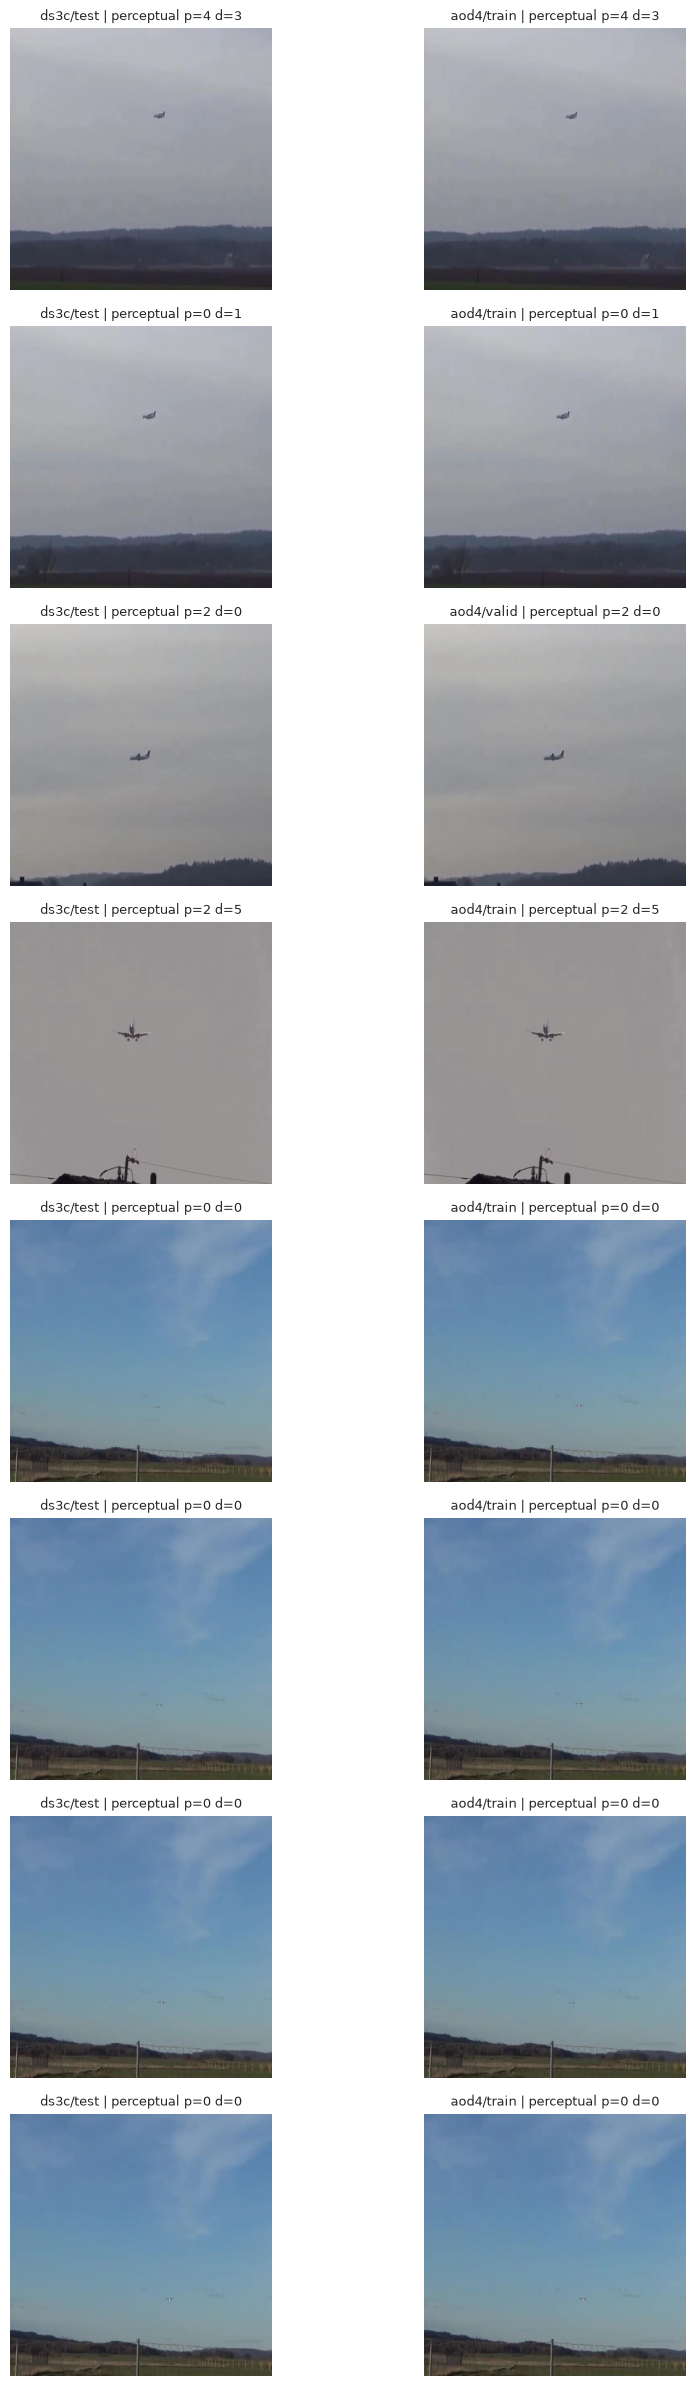

In [9]:
def show_duplicate_examples(edges, samples, n=8):
    by_uid = {r.uid: r for r in samples}
    cross = [e for e in edges if by_uid[e['left']].source != by_uid[e['right']].source]
    chosen = sorted(cross, key=lambda e: (e['kind'] != 'perceptual', e['left']))[:n]
    if not chosen:
        logger.info('Brak zapisanych par międzyzbiorowych do wizualizacji.')
        return
    fig, axes = plt.subplots(len(chosen), 2, figsize=(10, 3 * len(chosen)), squeeze=False)
    for row, edge in zip(axes, chosen):
        for ax, uid in zip(row, (edge['left'], edge['right'])):
            sample = by_uid[uid]
            with Image.open(sample.image) as image:
                ax.imshow(image.convert('RGB'))
            ax.axis('off')
            ax.set_title(f"{sample.source}/{sample.split} | {edge['kind']} p={edge['phash_distance']} d={edge['dhash_distance']}", fontsize=9)
    fig.tight_layout()
    save_figure(fig, 'duplicate_pairs_review')

show_duplicate_examples(duplicate_edges, records)

## 5. Opcjonalne brakujące ptaki: filtracja lub pseudoetykiety

Domyślnie `BIRD_MODE='off'`: wynik jawnie raportuje nierozwiązane ryzyko brakujących
ptaków. Aby włączyć, ustaw lokalne `BIRD_WEIGHTS` i tryb `filter` (usuń próbkę)
lub `append` (dodaj ptaka jako ID=1). Nie pobieramy ani nie trenujemy modelu automatycznie.
Model nauczyciel powinien być trenowany wyłącznie na treningu AOD-4, bez benchmarku.
COCO ma `bird=14`, AOD-4 `bird=1`; kod ustala ID po `model.names` i sprawdza typ zadania.

Próg jest ściśle `conf > 0.45`. Wykrycia nakładające się na istniejący obiekt innej
klasy (IoU lub pokrycie mniejszej ramki) są zapisywane jako konflikt i filtrują próbkę,
zamiast tworzyć dwie sprzeczne etykiety. Brak detekcji nie dowodzi braku ptaka;
pseudoetykiety wymagają inspekcji. Oryginalne etykiety nigdy nie są modyfikowane.

In [10]:
def xywh_to_xyxy(box):
    x, y, w, h = box
    return np.array([x - w / 2, y - h / 2, x + w / 2, y + h / 2], dtype=float)

def overlap_scores(a, b):
    a, b = xywh_to_xyxy(a), xywh_to_xyxy(b)
    inter = float(np.prod(np.maximum(0, np.minimum(a[2:], b[2:]) - np.maximum(a[:2], b[:2]))))
    aa, ab = float(np.prod(a[2:] - a[:2])), float(np.prod(b[2:] - b[:2]))
    return inter / max(aa + ab - inter, 1e-12), inter / max(min(aa, ab), 1e-12)

def process_bird_candidates(sample, detections, mode, conf=BIRD_CONF):
    additions, audit, reject = [], [], False
    for score, coords in detections:
        if not float(score) > conf:
            continue
        box = validate_hbb_line('1 ' + ' '.join(map(str, coords)), {1: 1})
        conflict = any(cls != 1 and (overlap_scores(coords, (x, y, w, h))[0] > 0.30 or
                                    overlap_scores(coords, (x, y, w, h))[1] > 0.60)
                       for cls, x, y, w, h in sample.boxes)
        covered = any(cls == 1 and overlap_scores(coords, (x, y, w, h))[0] > 0.5
                      for cls, x, y, w, h in sample.boxes + additions)
        action = 'already_labeled' if covered else 'conflict_filter' if conflict else mode
        audit.append({'uid': sample.uid, 'confidence': float(score), 'xywh': list(map(float, coords)), 'action': action})
        if conflict or (not covered and mode == 'filter'):
            reject = True
        elif not covered and mode == 'append':
            additions.append(box)
    return additions, audit, reject

def bird_filter(samples, decisions, weights, mode='filter', batch_size=16, device='cpu'):
    if mode not in {'filter', 'append'}:
        raise ValueError(mode)
    checkpoint = Path(weights).expanduser().resolve()
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    from ultralytics import YOLO
    model = YOLO(str(checkpoint))
    if model.task != 'detect':
        raise ValueError(f'Wymagany detektor HBB; model.task={model.task}')
    names = model.names
    if isinstance(names, list):
        names = dict(enumerate(names))
    bird_ids = [int(k) for k, value in names.items() if str(value).strip().casefold() == 'bird']
    if len(bird_ids) != 1:
        raise ValueError(f'Model nie ma jednoznacznej klasy bird: {names}')
    bird_id = bird_ids[0]
    write_json(REPORT / 'bird_teacher.json', {'checkpoint': str(checkpoint), 'sha256': sha256_file(checkpoint),
               'names': names, 'bird_id': bird_id, 'mode': mode, 'conf_strict_gt': BIRD_CONF, 'device': device})
    wanted = set(decisions.loc[decisions.keep & (decisions.source == 'ds3c'), 'uid'])
    candidates = [r for r in samples if r.uid in wanted]
    audit, rejected = [], set()
    for start in tqdm(range(0, len(candidates), batch_size), desc='Wykrywanie brakujących ptaków'):
        batch = candidates[start:start + batch_size]
        results = list(model.predict(source=[str(r.image) for r in batch], classes=[bird_id],
                      conf=BIRD_CONF, imgsz=640, device=device, stream=True, verbose=False, save=False))
        if len(results) != len(batch):
            raise RuntimeError('Niekompletna inferencja nauczyciela.')
        for sample, result in zip(batch, results):
            if Path(result.path).resolve() != sample.image.resolve():
                raise RuntimeError('Wynik nauczyciela nie odpowiada próbce.')
            detections = [] if result.boxes is None else list(zip(result.boxes.conf.cpu().numpy(), result.boxes.xywhn.cpu().numpy()))
            additions, rows, reject = process_bird_candidates(sample, detections, mode)
            sample.pseudo = additions
            audit.extend(rows)
            if reject:
                rejected.add(sample.uid)
    decisions = decisions.copy()
    mask = decisions.uid.isin(rejected)
    decisions.loc[mask, ['keep', 'reason']] = [False, 'bird_filter_or_conflict']
    pd.DataFrame(audit, columns=['uid', 'confidence', 'xywh', 'action']).to_csv(REPORT / 'bird_detections.csv', index=False)
    return decisions

if BIRD_MODE == 'off':
    logger.warning('Moduł ptaków wyłączony: brakujące etykiety bird pozostają ograniczeniem zbioru ds3c.')
elif BIRD_MODE in {'filter', 'append'} and BIRD_WEIGHTS is not None:
    decision_frame = bird_filter(records, decision_frame, BIRD_WEIGHTS, BIRD_MODE, device=BIRD_DEVICE)
else:
    raise ValueError('Ustaw BIRD_MODE off/filter/append i lokalne BIRD_WEIGHTS dla aktywnego trybu.')

2026-10-26 21:19:17,576 WARNING Moduł ptaków wyłączony: brakujące etykiety bird pozostają ograniczeniem zbioru ds3c.


## 6. Plan, kontrola regresji i bezpieczne kopiowanie

Plan zawiera pochodzenie każdej próbki, przyczynę decyzji i hashe plików.
Nazwy mają prefiks źródła, oryginalny split oraz skrót UID, dlatego także dwie próbki
o tej samej nazwie w różnych splitach nie nadpiszą się po przeniesieniu do treningu.
Sprawdzamy kolizje również bez rozróżniania wielkości liter.

Kopiowanie używa `shutil.copy2`, nigdy dowiązań do źródeł. Nowy zbiór powstaje w
katalogu staging na tym samym systemie plików, jest w pełni audytowany, a dopiero potem
otrzymuje nazwę docelową. Blokada zapobiega równoczesnym publikacjom tego potoku.
Wyjątek usuwa wyłącznie własny staging i blokadę. Istniejący wynik o innym planie
powoduje błąd, bez kasowania czy modyfikacji jego plików.

In [11]:
def run_regression_checks():
    mapping = {0: 0, 1: 2, 2: 3}
    assert validate_hbb_line('1 0.5 0.5 0.2 0.1', mapping)[0] == 2
    bad_lines = ['1 nan 0.5 0.2 0.2', '1 0.5 0.5 0 0.2', '1.5 0.5 0.5 0.2 0.2',
                 '3 0.5 0.5 0.2 0.2', '1 0.99 0.5 0.2 0.2', '1 0.5 0.5 0.2 0.2 0.1 0.1',
                 '1 0.5 0.5 inf 0.1', '-1 0.5 0.5 0.1 0.1']
    for line in bad_lines:
        try:
            validate_hbb_line(line, mapping)
        except ValueError:
            pass
        else:
            raise AssertionError(f'Nie odrzucono: {line}')
    tree = BKTree()
    rng = np.random.default_rng(SEED)
    values = list(map(int, rng.integers(0, 2**16, 200))) + [0, 1, 3, 7, 15]
    for i, value in enumerate(values):
        tree.add(value, i)
    for query in values[::7]:
        found = {i for _, i in tree.search(query, 4)}
        brute = {i for i, value in enumerate(values) if (query ^ value).bit_count() <= 4}
        assert found == brute, 'BK-tree pominęło kandydata.'
    uf = UnionFind(3)
    uf.union(0, 1)
    uf.union(1, 2)
    assert uf.find(0) == uf.find(2), 'Brak domknięcia przechodniego.'
    assert video_group('V_DRONE_012122_045_png_jpg.rf.abc') == video_group('V_DRONE_012122_180_png.rf.def')
    assert video_group('yt-WqLL0-xBF8g-0032_jpg.rf.abc') == 'yt-wqll0-xbf8g'
    assert video_group('ordinary_photo_123') is None
    sample = Sample('synthetic', 'ds3c', 'train', Path('unused.jpg'), None)
    additions, audit, reject = process_bird_candidates(sample, [(0.45, [0.5, 0.5, 0.2, 0.2]),
                                                   (0.9, [0.5, 0.5, 0.2, 0.2])], 'append')
    assert len(additions) == 1 and additions[0][0] == 1 and not reject
    sample.boxes = [(2, 0.5, 0.5, 0.2, 0.2)]
    additions, audit, reject = process_bird_candidates(sample, [(0.9, [0.5, 0.5, 0.2, 0.2])], 'append')
    assert reject and not additions and audit[0]['action'] == 'conflict_filter'
    # Całkowicie identyczne obrazy o innych nazwach, bliski łańcuch i daleki hash.
    synthetic = [Sample(str(i), 'aod4', 'train', Path(f'{i}.jpg'), None) for i in range(4)]
    for i, r in enumerate(synthetic):
        r.image_sha = f'file-{i}'
        r.pixel_sha = f'pixel-{i}'
        r.phash = [0, 15, 255, (1 << 64) - 1][i]
        r.dhash = r.phash
    duplicate_test, _ = build_duplicate_graph(synthetic, phash_radius=4, dhash_radius=6)
    assert duplicate_test.find(0) == duplicate_test.find(2)
    assert duplicate_test.find(0) != duplicate_test.find(3)
    return {'status': 'passed', 'covers': ['HBB', 'remapping', 'NaN/Inf', 'bounds', 'BK-tree vs brute force',
             'transitive duplicates', 'video names', 'strict bird threshold', 'bird conflicts']}

regression_result = run_regression_checks()
write_json(REPORT / 'regression_checks.json', regression_result)
display(regression_result)

Graf duplikatów:   0%|          | 0/4 [00:00<?, ?it/s]

Graf duplikatów: 100%|██████████| 4/4 [00:00<00:00, 33026.02it/s]

{'status': 'passed',
 'covers': ['HBB',
  'remapping',
  'NaN/Inf',
  'bounds',
  'BK-tree vs brute force',
  'transitive duplicates',
  'video names',
  'strict bird threshold',
  'bird conflicts']}

In [12]:
by_uid = {r.uid: r for r in records}

def output_label_bytes(sample):
    original = sample.label.read_bytes()
    if hashlib.sha256(original).hexdigest() != sample.label_sha:
        raise RuntimeError(f'Etykieta zmieniła się podczas pracy: {sample.label}')
    if sample.source == 'aod4':
        return original  # benchmark oraz poprawne etykiety AOD train są bajtowo identyczne
    boxes = sample.boxes + sample.pseudo
    if not boxes:
        return b''  # zachowanie jawnych negative samples
    return (''.join(f'{cls} ' + ' '.join(f'{v:.12g}' for v in (x, y, w, h)) + '\n'
                    for cls, x, y, w, h in boxes)).encode('utf-8')

plan = []
for row in decision_frame.loc[decision_frame.keep].sort_values('uid').to_dict('records'):
    sample = by_uid[row['uid']]
    token = hashlib.sha256(sample.uid.encode('utf-8')).hexdigest()[:12]
    stem = f'{sample.source}_{sample.split}_{sample.image.stem}_{token}'
    image_rel = f"{row['output_split']}/images/{stem}{sample.image.suffix.lower()}"
    label_rel = f"{row['output_split']}/labels/{stem}.txt"
    label_bytes = output_label_bytes(sample)
    plan.append({'uid': sample.uid, 'source': sample.source, 'source_split': sample.split,
                 'split': row['output_split'], 'source_image': str(sample.image), 'source_label': str(sample.label),
                 'image': image_rel, 'label': label_rel, 'image_sha256': sample.image_sha,
                 'label_sha256': hashlib.sha256(label_bytes).hexdigest(), 'original_label_sha256': sample.label_sha,
                 'background': not bool(sample.boxes + sample.pseudo), 'original_zero_bytes': sample.zero_bytes,
                 'instances': len(sample.boxes + sample.pseudo), 'pseudo_instances': len(sample.pseudo),
                 'duplicate_component': int(row['duplicate_component']), 'leakage_component': int(row['leakage_component'])})

for split in SPLITS:
    subset = [p for p in plan if p['split'] == split]
    if not subset:
        raise RuntimeError(f'Po filtracji split {split} jest pusty.')
    names = [Path(p['image']).stem for p in subset]
    if len(names) != len(set(names)) or len(names) != len({n.casefold() for n in names}):
        raise RuntimeError(f'Kolizja nazw w {split}.')
    if split != 'train':
        expected = {r.uid for r in records if r.source == 'aod4' and r.split == split}
        assert {p['uid'] for p in subset} == expected
        assert all(p['source'] == 'aod4' and p['source_split'] == split and
                   p['label_sha256'] == p['original_label_sha256'] for p in subset)

params = {'target_classes': TARGET, 'source_mappings': MAPPINGS, 'phash_radius': PHASH_RADIUS,
          'dhash_radius': DHASH_RADIUS, 'protect_known_video_groups': PROTECT_KNOWN_VIDEO_GROUPS,
          'bird_mode': BIRD_MODE, 'bird_conf': BIRD_CONF, 'seed': SEED,
          'bird_checkpoint_sha256': sha256_file(Path(BIRD_WEIGHTS).expanduser().resolve()) if BIRD_MODE != 'off' else None,
          'hash_algorithm': 'imagehash.phash(hash_size=8), dhash(hash_size=8); RGB pixel SHA256',
          'output': str(OUTPUT)}
plan_hash = hashlib.sha256(json.dumps({'params': params, 'plan': plan}, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
manifest = {'schema_version': 1, 'plan_sha256': plan_hash, 'parameters': params,
            'report_directory': str(REPORT), 'created_utc': datetime.now(timezone.utc).isoformat(), 'samples': plan}
write_json(REPORT / 'manifest.json', manifest)
decision_frame.to_csv(REPORT / 'all_decisions.csv', index=False)
save_table(pd.DataFrame(plan).groupby(['split', 'source']).agg(images=('uid', 'size'),
           backgrounds=('background', 'sum'), instances=('instances', 'sum'), pseudo_instances=('pseudo_instances', 'sum')).reset_index(), 'planned_dataset', latex=True)

,split,source,images,backgrounds,instances,pseudo_instances
0,test,aod4,2241,56,3171,0
1,train,aod4,1565,33,3751,0
2,train,ds3c,1395,0,1469,0
3,valid,aod4,4514,125,6369,0


In [13]:
def audit_dataset(folder, manifest, verify_source=True):
    folder = Path(folder)
    expected = manifest['samples']
    config = yaml.safe_load((folder / 'dataset.yaml').read_text(encoding='utf-8'))
    if (config.get('path') != str(OUTPUT) or config.get('train') != 'train/images'
            or config.get('val') != 'valid/images' or config.get('test') != 'test/images'
            or normalize_names(config.get('names')) != TARGET):
        raise RuntimeError('Niezgodny dataset.yaml')
    totals = []
    for split in SPLITS:
        planned = [p for p in expected if p['split'] == split]
        expected_images = {p['image'] for p in planned}
        expected_labels = {p['label'] for p in planned}
        image_paths = [p for p in (folder / split / 'images').rglob('*') if p.is_file()]
        label_paths = [p for p in (folder / split / 'labels').rglob('*') if p.is_file()]
        if {p.relative_to(folder).as_posix() for p in image_paths} != expected_images:
            raise RuntimeError(f'Niezgodny zestaw obrazów: {split}')
        if {p.relative_to(folder).as_posix() for p in label_paths} != expected_labels:
            raise RuntimeError(f'Niezgodny zestaw etykiet: {split}')
        if {p.stem for p in image_paths} != {p.stem for p in label_paths}:
            raise RuntimeError(f'Niezgodne parowanie case-sensitive: {split}')
        if len(image_paths) != len({p.stem.casefold() for p in image_paths}):
            raise RuntimeError(f'Kolizje nazw: {split}')
        counts, backgrounds = Counter(), 0
        for item in tqdm(planned, desc=f'Audyt {split}'):
            image, label = folder / item['image'], folder / item['label']
            if image.is_symlink() or label.is_symlink():
                raise RuntimeError('Wynik zawiera dowiązanie.')
            if sha256_file(image) != item['image_sha256'] or sha256_file(label) != item['label_sha256']:
                raise RuntimeError(f'Niezgodny hash: {item["uid"]}')
            if verify_source:
                if sha256_file(item['source_image']) != item['image_sha256'] or sha256_file(item['source_label']) != item['original_label_sha256']:
                    raise RuntimeError(f'Źródło zmieniło się podczas pracy: {item["uid"]}')
            with Image.open(image) as im:
                im.verify()
            boxes = [validate_hbb_line(line, {i: i for i in TARGET})
                     for line in label.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
            if len(boxes) != item['instances']:
                raise RuntimeError(f'Niezgodna liczba instancji: {item["uid"]}')
            if item['original_zero_bytes'] and not item['pseudo_instances'] and label.stat().st_size != 0:
                raise RuntimeError('Utracono etykietę tła 0 B.')
            counts.update(b[0] for b in boxes)
            backgrounds += not boxes
            if split != 'train' and (item['source'] != 'aod4' or item['source_split'] != split or
                                    item['label_sha256'] != item['original_label_sha256']):
                raise RuntimeError('Naruszona integralność benchmarku.')
        totals.append({'split': split, 'images': len(planned), 'backgrounds': backgrounds,
                       **{TARGET[c]: counts[c] for c in TARGET}})
    train_components = {p['leakage_component'] for p in expected if p['split'] == 'train'}
    benchmark_components = {p['leakage_component'] for p in expected if p['split'] != 'train'}
    if train_components & benchmark_components:
        raise RuntimeError('Wyciek do train na poziomie hashy/sekwencji.')
    return pd.DataFrame(totals)

def materialize_dataset(destination, manifest):
    destination = Path(destination)
    for source in (AOD_ROOT, DS_ROOT):
        if destination.resolve().is_relative_to(source.resolve()) or source.resolve().is_relative_to(destination.resolve()):
            raise ValueError('Cel nie może pokrywać się z katalogiem źródłowym.')
    if destination.is_symlink():
        raise RuntimeError('Katalog docelowy jest dowiązaniem.')
    destination.parent.mkdir(parents=True, exist_ok=True)
    lock = destination.parent / f'.{destination.name}.lock'
    # O_EXCL jest atomowe: nie przejmujemy ani nie usuwamy cudzej blokady.
    descriptor = os.open(lock, os.O_WRONLY | os.O_CREAT | os.O_EXCL, 0o600)
    staging = None
    try:
        with os.fdopen(descriptor, 'w', encoding='utf-8') as stream:
            json.dump({'pid': os.getpid(), 'run': RUN_ID, 'plan': manifest['plan_sha256']}, stream)
            stream.flush()
            os.fsync(stream.fileno())
        if destination.exists():
            saved_path = destination / 'merge_manifest.json'
            if not saved_path.is_file():
                raise FileExistsError(f'Istniejący cel bez manifestu: {destination}')
            saved = json.loads(saved_path.read_text(encoding='utf-8'))
            if saved.get('plan_sha256') != manifest['plan_sha256'] or saved.get('samples') != manifest['samples']:
                raise FileExistsError('Istniejący wynik ma inny plan. Ustaw nowy OUTPUT; nic nie nadpisano.')
            logger.info('Identyczny plan już istnieje: weryfikacja bez nadpisywania.')
            return audit_dataset(destination, manifest)
        required = sum(Path(p['source_image']).stat().st_size + Path(p['source_label']).stat().st_size + 512 for p in manifest['samples'])
        if shutil.disk_usage(destination.parent).free < required * 1.15 + 64 * 1024**2:
            raise OSError('Niewystarczające miejsce na niezależną kopię zbioru.')
        staging = Path(tempfile.mkdtemp(prefix=f'.{destination.name}.staging-', dir=destination.parent))
        for split in SPLITS:
            (staging / split / 'images').mkdir(parents=True)
            (staging / split / 'labels').mkdir(parents=True)
        for item in tqdm(manifest['samples'], desc='Kopiowanie do staging'):
            sample = by_uid[item['uid']]
            image_target, label_target = staging / item['image'], staging / item['label']
            if image_target.exists() or label_target.exists():
                raise FileExistsError(f'Kolizja podczas kopiowania: {item["uid"]}')
            shutil.copy2(sample.image, image_target)
            if sample.source == 'aod4':
                shutil.copy2(sample.label, label_target)
            else:
                with label_target.open('xb') as stream:
                    stream.write(output_label_bytes(sample))
        config = {'path': str(destination.resolve()), 'train': 'train/images', 'val': 'valid/images',
                  'test': 'test/images', 'names': TARGET}
        (staging / 'dataset.yaml').write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True), encoding='utf-8')
        write_json(staging / 'merge_manifest.json', manifest)
        audited = audit_dataset(staging, manifest)
        audited.to_csv(staging / 'merge_summary.csv', index=False)
        write_json(staging / 'merge_audit.json', {'plan_sha256': manifest['plan_sha256'], 'status': 'passed',
                   'benchmark_byte_preserved': True, 'train_leakage_under_configured_checks': False,
                   'valid_test_overlap_components': len(benchmark_relations), 'bird_mode': BIRD_MODE,
                   'report_directory': str(REPORT)})
        if destination.exists():
            raise FileExistsError('Cel pojawił się w trakcie kopiowania; eksport przerwany.')
        staging.rename(destination)
        staging = None
        logger.info('Opublikowano zweryfikowany zbiór: %s', destination)
        return audited
    finally:
        if staging is not None and staging.exists():
            shutil.rmtree(staging)
        lock.unlink(missing_ok=True)

if COMMIT_DATASET:
    final_inventory = materialize_dataset(OUTPUT, manifest)
    save_table(final_inventory, 'output_inventory_verified', latex=True)
else:
    logger.info('COMMIT_DATASET=False: plan i analizy zapisane, bez kopiowania.')

2026-10-26 21:19:19,007 INFO Identyczny plan już istnieje: weryfikacja bez nadpisywania.


Audyt train:   0%|          | 0/2960 [00:00<?, ?it/s]

Audyt train:   3%|▎         | 80/2960 [00:00<00:03, 795.93it/s]

Audyt train:   6%|▌         | 172/2960 [00:00<00:03, 868.27it/s]

Audyt train:   9%|▉         | 259/2960 [00:00<00:04, 640.77it/s]

Audyt train:  11%|█         | 329/2960 [00:00<00:05, 452.47it/s]

... (112 outputs left out)

Audyt test:  74%|███████▍  | 1664/2241 [00:00<00:00, 3453.57it/s]

Audyt test:  90%|████████▉ | 2012/2241 [00:00<00:00, 3433.19it/s]

Audyt test: 100%|██████████| 2241/2241 [00:00<00:00, 3150.87it/s]

,split,images,backgrounds,airplane,bird,drone,helicopter
0,train,2960,33,485,3520,996,219
1,valid,4514,125,1625,1557,1602,1585
2,test,2241,56,767,821,796,787


## 7. Tabele i wykresy do rozdziału 3/4

Rozdzielamy obrazy od instancji. „Przed” oznacza surowe ID źródłowe po semantycznym
remapowaniu, także linie wymagające odrzucenia; „po walidacji” obejmuje tylko całe
poprawne próbki. „Po” jest liczone z faktycznie zapisanych etykiet, jeżeli wykonano eksport.
Porównanie treningu pokazuje osobno bazowy AOD oraz wkład ds3c; benchmark nie zwiększa
liczby próbek treningowych. PNG 300 dpi, PDF i tabele CSV/HTML/LaTeX są w katalogu raportu.

,ID,Klasa,AOD przed (całość),ds3c przed (całość),Po walidacji (łącznie),AOD train przed,AOD train po,ds3c dodane do train,Merged train po,Merged całość po
0,0,airplane,7900,2535,10432,5508,9,476,485,2877
1,1,bird,7900,0,7900,5522,3520,0,3520,5898
2,2,drone,7898,5854,13749,5500,3,993,996,3394
3,3,helicopter,7900,2628,10528,5528,219,0,219,2591


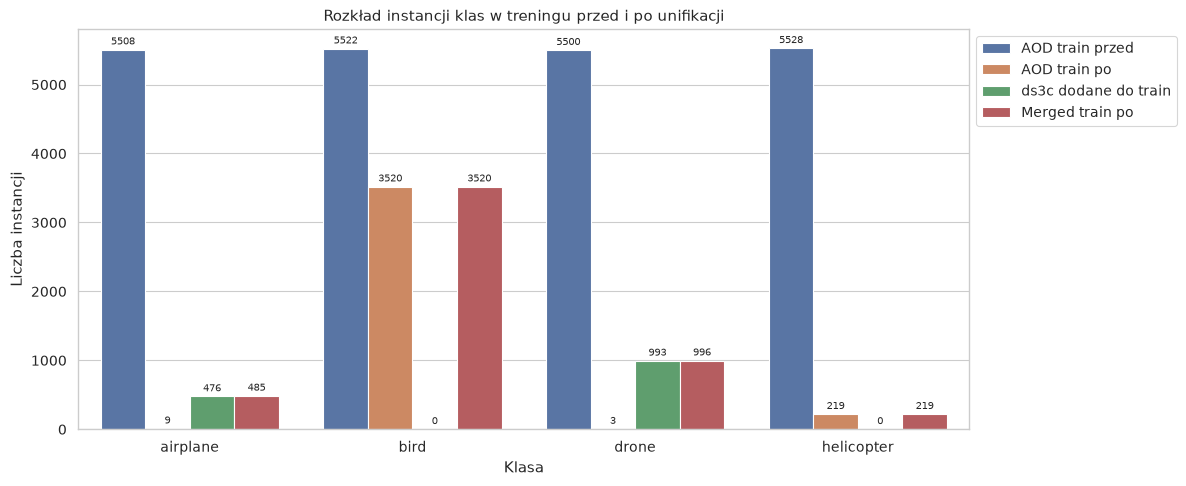

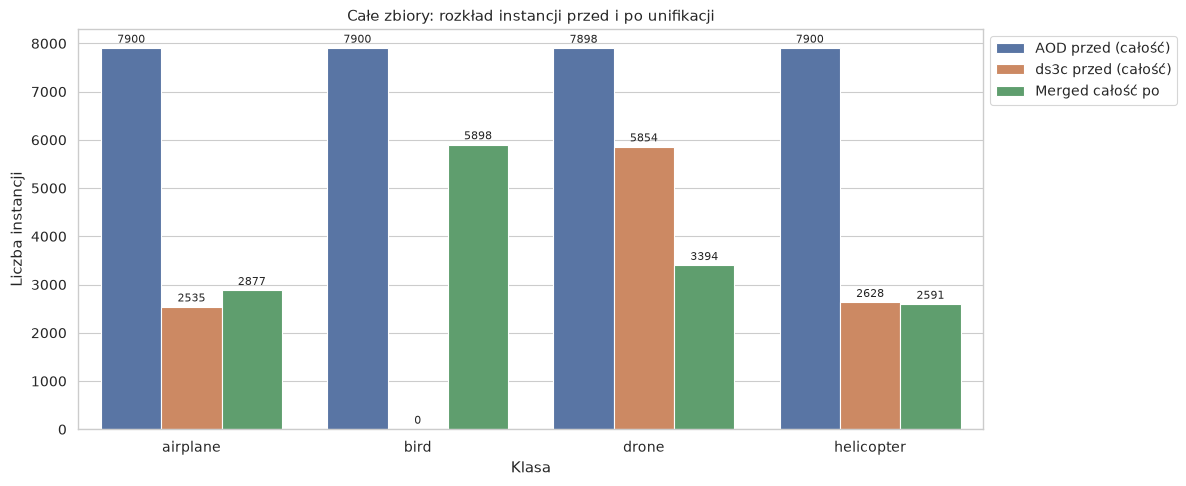

**Interpretacja geometrii:** porównaj mediany i 95. percentyle poniżej. Duże ramki mogą wynikać z bliskiego obiektu lub ze zbyt dużego marginesu; sam rozkład wymiarów nie rozstrzyga przyczyny.

w         h
source                         
aod4   0.50  0.056152  0.058105
       0.95  0.169922  0.134351
ds3c   0.50  0.057813  0.054688
       0.95  0.919357  0.570464

**Raport:** `/home/hubert/ISA/INŻ/research/reports/dataset_unificator/20261026T201531_60a225c2`  
**Wynik:** `/home/hubert/ISA/INŻ/datasets/AOD_4_merged`  
**Plan SHA-256:** `e50f1c1d2a0cd97156e0aaa9ee3fd503cee10bb58358194ebb180b50b0a1e95b`  
**Powiązania valid–test:** 479 składowych (różne rodzaje audytu mogą się pokrywać).  
**Moduł bird:** `off`. Nierozpoznane sekwencje i skuteczność hashy wymagają dalszej oceny.

In [14]:
def count_instances(samples, cls, predicate, raw=False):
    if raw:
        return sum(r.raw_counts[cls] for r in samples if predicate(r))
    return sum(sum(b[0] == cls for b in r.boxes + r.pseudo) for r in samples if predicate(r))

selected_uids = {p['uid'] for p in plan}
selected_train = {p['uid'] for p in plan if p['split'] == 'train'}
summary_rows = []
for cls, name in TARGET.items():
    if COMMIT_DATASET:
        after_all = int(final_inventory[name].sum())
        after_train = int(final_inventory.loc[final_inventory.split == 'train', name].sum())
    else:
        after_all = count_instances(records, cls, lambda r: r.uid in selected_uids)
        after_train = count_instances(records, cls, lambda r: r.uid in selected_train)
    summary_rows.append({'ID': cls, 'Klasa': name,
        'AOD przed (całość)': count_instances(records, cls, lambda r: r.source == 'aod4', raw=True),
        'ds3c przed (całość)': count_instances(records, cls, lambda r: r.source == 'ds3c', raw=True),
        'Po walidacji (łącznie)': count_instances(records, cls, lambda r: r.valid),
        'AOD train przed': count_instances(records, cls, lambda r: r.source == 'aod4' and r.split == 'train', raw=True),
        'AOD train po': count_instances(records, cls, lambda r: r.source == 'aod4' and r.uid in selected_train),
        'ds3c dodane do train': count_instances(records, cls, lambda r: r.source == 'ds3c' and r.uid in selected_train),
        'Merged train po': after_train, 'Merged całość po': after_all})
class_summary = pd.DataFrame(summary_rows)
save_table(class_summary, 'class_distribution_before_after', latex=True)
plot_columns = ['AOD train przed', 'AOD train po', 'ds3c dodane do train', 'Merged train po']
plot_data = class_summary.melt(id_vars=['ID', 'Klasa'], value_vars=plot_columns,
                               var_name='Etap', value_name='Instancje')
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_data, x='Klasa', y='Instancje', hue='Etap', hue_order=plot_columns, ax=ax)
ax.set(title='Rozkład instancji klas w treningu przed i po unifikacji', xlabel='Klasa', ylabel='Liczba instancji')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=7, padding=2)
ax.legend(title=None, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
save_figure(fig, 'class_distribution_before_after')

overall_columns = ['AOD przed (całość)', 'ds3c przed (całość)', 'Merged całość po']
overall_data = class_summary.melt(id_vars=['ID', 'Klasa'], value_vars=overall_columns,
                                 var_name='Zbiór', value_name='Instancje')
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=overall_data, x='Klasa', y='Instancje', hue='Zbiór', hue_order=overall_columns, ax=ax)
ax.set(title='Całe zbiory: rozkład instancji przed i po unifikacji', xlabel='Klasa', ylabel='Liczba instancji')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=8, padding=2)
ax.legend(title=None, loc='upper left', bbox_to_anchor=(1, 1))
fig.tight_layout()
save_figure(fig, 'class_distribution_all_splits')

drone_quantiles = drone_boxes.groupby('source')[['w', 'h']].quantile([0.5, 0.95])
display(Markdown('**Interpretacja geometrii:** porównaj mediany i 95. percentyle poniżej. '
                 'Duże ramki mogą wynikać z bliskiego obiektu lub ze zbyt dużego marginesu; '
                 'sam rozkład wymiarów nie rozstrzyga przyczyny.'))
display(drone_quantiles)
drone_quantiles.to_csv(REPORT / 'drone_median_p95.csv')

limitations = {
    'benchmark_preserved': 'Wszystkie oryginalne obrazy i etykiety valid/test AOD-4: identyczne bajty, nowe prefiksy nazw.',
    'valid_test_overlap_components': len(benchmark_relations),
    'valid_test_independence': 'Niepotwierdzona; patrz benchmark_valid_test_overlap.csv.',
    'hashes': f'pHash <= {PHASH_RADIUS} AND dHash <= {DHASH_RADIUS}; możliwe fałszywe dopasowania i pominięcia.',
    'sequence_policy': 'Rozpoznane sekwencje chronione; nieznane pochodzenie nie gwarantuje braku wycieku.',
    'bird_mode': BIRD_MODE,
    'bird_missing_labels': 'Nierozwiązane przy off; brak detekcji nauczyciela również nie dowodzi braku ptaków.',
    'tightness': 'Ręczna ocena: tightness_aod4_16.png, tightness_ds3c_16.png i drone_largest_boxes_review.csv.',
    'output_written': COMMIT_DATASET,
}
write_json(REPORT / 'limitations.json', limitations)
display(Markdown(f"""**Raport:** `{REPORT}`  
**Wynik:** `{OUTPUT}`  
**Plan SHA-256:** `{plan_hash}`  
**Powiązania valid–test:** {len(benchmark_relations)} składowych (różne rodzaje audytu mogą się pokrywać).  
**Moduł bird:** `{BIRD_MODE}`. Nierozpoznane sekwencje i skuteczność hashy wymagają dalszej oceny."""))

## 8. Higiena cache i oficjalna kontrola Ultralytics — ostatnia komórka

Czyszczenie `*.cache` dotyczy wyłącznie zbioru wynikowego, nigdy oryginalnych źródeł.
`check_det_dataset(..., autodownload=False)` sprawdza YAML i ścieżki; nie zastępuje
pełnego audytu etykiet, parowania, obrazów i benchmarku wykonanego powyżej.
Nie jest to trening ani pomiar jakości YOLO26. Tryb ptaków pozostaje opcjonalny.

Źródła techniczne: [format detekcyjny YOLO](https://docs.ultralytics.com/datasets/detect/),
[check_det_dataset](https://docs.ultralytics.com/reference/data/utils/#ultralytics.data.utils.check_det_dataset),
[inferencja i Results](https://docs.ultralytics.com/modes/predict/),
[COCO: bird=14](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/datasets/coco.yaml).

In [15]:
if COMMIT_DATASET:
    for cache in OUTPUT.rglob('*.cache'):
        if cache.is_file() and not cache.is_symlink():
            cache.unlink()
            logger.info('Usunięto cache wyniku: %s', cache)
    # Konfiguracja biblioteki w katalogu raportu, bez zapisu w źródłach / katalogu domowym.
    os.environ['YOLO_CONFIG_DIR'] = str(REPORT / 'ultralytics_config')
    os.environ['YOLO_AUTOINSTALL'] = 'false'
    os.environ['YOLO_OFFLINE'] = 'true'
    from ultralytics.data.utils import check_det_dataset
    checked = check_det_dataset(str(OUTPUT / 'dataset.yaml'), autodownload=False)
    if normalize_names(checked['names']) != TARGET:
        raise RuntimeError('Ultralytics odczytało inne klasy.')
    for key, split in [('train', 'train'), ('val', 'valid'), ('test', 'test')]:
        if Path(checked[key]).resolve() != (OUTPUT / split / 'images').resolve():
            raise RuntimeError(f'Ultralytics odczytało inną ścieżkę {key}.')
    readiness = {'status': 'passed', 'check_det_dataset': True, 'autodownload': False,
                 'dataset': str(OUTPUT / 'dataset.yaml'), 'plan_sha256': plan_hash,
                 'ultralytics_version': version('ultralytics'), 'bird_mode': BIRD_MODE,
                 'valid_test_overlap_components': len(benchmark_relations)}
    write_json(REPORT / 'readiness.json', readiness)
    logger.info('Zbiór gotowy strukturalnie do treningu YOLO26; ograniczenia metodologiczne: limitations.json.')
    display(readiness)
else:
    logger.info('Tryb analizy: oficjalna kontrola wymaga COMMIT_DATASET=True.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/hubert/ISA/INŻ/research/reports/dataset_unificator/20261026T201531_60a225c2/ultralytics_config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


2026-10-26 21:19:40,239 INFO Zbiór gotowy strukturalnie do treningu YOLO26; ograniczenia metodologiczne: limitations.json.


{'status': 'passed',
 'check_det_dataset': True,
 'autodownload': False,
 'dataset': '/home/hubert/ISA/INŻ/datasets/AOD_4_merged/dataset.yaml',
 'plan_sha256': 'e50f1c1d2a0cd97156e0aaa9ee3fd503cee10bb58358194ebb180b50b0a1e95b',
 'ultralytics_version': '8.4.190',
 'bird_mode': 'off',
 'valid_test_overlap_components': 479}